## Вводные по кейсу

# Описание данных

## Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

## Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

## Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


## Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |



## Описание событий

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


## Выручка маркетплейса = 5% от total_price

# Блок кода и расчета метрик

### 1. Загрузка и предобработка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest

In [2]:
orders = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders.csv')
campaign_costs = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_campaign_costs.csv')
users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events.csv')

In [3]:
# Описание данных orders
print("Первые 5 строк orders:")
display(orders.head())

print("\nИнформация о данных orders:")
orders.info()

print("\nПропуски orders:")
print(orders.isna().sum())

print("\nПолные дубликаты строк orders:")
print(orders.duplicated().sum())

print("\n=================================")

# Описание данных campaign_costs
print("\nПервые 5 строк campaign_costs:")
display(campaign_costs.head())

print("\nИнформация о данных campaign_costs:")
campaign_costs.info()

print("\nПропуски campaign_costs:")
print(campaign_costs.isna().sum())

print("\nПолные дубликаты строк campaign_costs:")
print(campaign_costs.duplicated().sum())

print("\n=================================")

# Описание данных users
print("\nПервые 5 строк users:")
display(users.head())

print("\nИнформация о данных users:")
users.info()

print("\nПропуски users:")
print(users.isna().sum())

print("\nПолные дубликаты строк users:")
print(users.duplicated().sum())

print("\n=================================")

# Описание данных events
print("\nПервые 5 строк events:")
display(events.head())

print("\nИнформация о данных events:")
events.info()

print("\nПропуски events:")
print(events.isna().sum())

print("\nПолные дубликаты строк events:")
print(events.duplicated().sum())

Первые 5 строк orders:


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52.000,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52.000,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38.000,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01



Информация о данных orders:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       31357 non-null  int64  
 1   user_id        31357 non-null  int64  
 2   order_date     31357 non-null  object 
 3   product_name   31357 non-null  object 
 4   quantity       31357 non-null  int64  
 5   unit_price     31357 non-null  float64
 6   total_price    31357 non-null  float64
 7   category_name  31357 non-null  object 
 8   order_week     31357 non-null  object 
 9   order_month    31357 non-null  object 
dtypes: float64(2), int64(3), object(5)
memory usage: 2.4+ MB

Пропуски orders:
order_id         0
user_id          0
order_date       0
product_name     0
quantity         0
unit_price       0
total_price      0
category_name    0
order_week       0
order_month      0
dtype: int64

Полные дубликаты строк orders:
0


Первые 5 строк 

,Unnamed: 0,acq_channel,spend_month,budget
0,0,Affiliate,2024-01-01,179343.3875
1,1,Affiliate,2024-02-01,175488.4875
2,2,Affiliate,2024-03-01,164543.4750
3,3,Affiliate,2024-04-01,186869.9750
4,4,Affiliate,2024-05-01,166443.7750



Информация о данных campaign_costs:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   88 non-null     int64  
 1   acq_channel  88 non-null     object 
 2   spend_month  88 non-null     object 
 3   budget       88 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 2.9+ KB

Пропуски campaign_costs:
Unnamed: 0     0
acq_channel    0
spend_month    0
budget         0
dtype: int64

Полные дубликаты строк campaign_costs:
0


Первые 5 строк users:


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01



Информация о данных users:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            44151 non-null  int64 
 1   registration_date  44151 non-null  object
 2   age                44151 non-null  int64 
 3   gender             44151 non-null  object
 4   region             44151 non-null  object
 5   acq_channel        44151 non-null  object
 6   buyer_segment      44151 non-null  object
 7   cohort_week        44151 non-null  object
 8   cohort_month       44151 non-null  object
dtypes: int64(2), object(7)
memory usage: 3.0+ MB

Пропуски users:
user_id              0
registration_date    0
age                  0
gender               0
region               0
acq_channel          0
buyer_segment        0
cohort_week          0
cohort_month         0
dtype: int64

Полные дубликаты строк users:
0


Первые 5 строк events:


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01



Информация о данных events:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   event_id      785859 non-null  int64 
 1   user_id       785859 non-null  int64 
 2   event_date    785859 non-null  object
 3   event_type    785859 non-null  object
 4   os            785859 non-null  object
 5   device        785859 non-null  object
 6   product_name  385740 non-null  object
 7   event_week    785859 non-null  object
 8   event_month   785859 non-null  object
dtypes: int64(2), object(7)
memory usage: 54.0+ MB

Пропуски events:
event_id             0
user_id              0
event_date           0
event_type           0
os                   0
device               0
product_name    400119
event_week           0
event_month          0
dtype: int64

Полные дубликаты строк events:
0


In [4]:
# Преобразование ячеек с датами orders
orders['order_date'] = pd.to_datetime(orders['order_date'])
orders['order_week'] = pd.to_datetime(orders['order_week'])
orders['order_month'] = pd.to_datetime(orders['order_month'])

# Преобразование ячеек с датами campaign_costs
campaign_costs['spend_month'] = pd.to_datetime(campaign_costs['spend_month'])

# Преобразование ячеек с датами users
users['registration_date'] = pd.to_datetime(users['registration_date'])
users['cohort_week'] = pd.to_datetime(users['cohort_week'])
users['cohort_month'] = pd.to_datetime(users['cohort_month'])

# Преобразование ячеек с датами events
events['event_date'] = pd.to_datetime(events['event_date'])
events['event_week'] = pd.to_datetime(events['event_week'])
events['event_month'] = pd.to_datetime(events['event_month'])

In [5]:
# Первичный анализ категориальных признаков
print("\nРегионы:", users['region'].unique())
print("\n=================================")
print("\nКаналы привлечения:", users['acq_channel'].unique())
print("\n=================================")
print("\nСегменты покупателей:", users['buyer_segment'].unique())
print("\n=================================")

print("\nСобытия events:", events['event_type'].unique())
print("\n=================================")
print("\nОперационные системы:", events['os'].unique())
print("\n=================================")
print("\nТипы устройств:", events['device'].unique())
print("\n=================================")

print("\nНаименования категорий товаров:", orders['category_name'].unique())
print("\n=================================")

print("\nКаналы привлечения:", campaign_costs['acq_channel'].unique())


Регионы: ['Москва' 'Санкт-Петербург' 'Краснодар' 'Другие регионы' 'Нижний Новгород'
 'Екатеринбург' 'Московская область' 'Новосибирск' 'Ростов-на-Дону']


Каналы привлечения: ['Google Ads' 'Email Marketing' 'Affiliate' 'SEO' 'Social Media' 'TikTok']


Сегменты покупателей: ['regular' 'rare' 'one_time' 'medium']


События events: ['page_view' 'product_view' 'product_click' 'add_to_cart' 'checkout_start'
 'checkout_complete' 'user_logout' 'search' 'category_view' 'filter_apply'
 'promo_view' 'wishlist_add' 'user_login' 'banner_click'
 'remove_from_cart']


Операционные системы: ['iOS' 'Windows' 'macOS' 'Android']


Типы устройств: ['mobile' 'desktop' 'tablet']


Наименования категорий товаров: ['Инструменты и садовый инвентарь' 'Продукты питания' 'Женская одежда'
 'Аксессуары для гаджетов' 'Одежда для спорта' 'Декор и освещение'
 'Детская одежда' 'Детские игрушки' 'Книги и канцтовары'
 'Медицинские товары' 'Косметика и парфюмерия' 'Товары для туризма'
 'Сумки и аксессуары' 'Автотовары' 

### 2. Построить обзор ключевых метрик

На этом этапе вам нужно выполнить верхнеуровневую оценку состояния продукта с помощью собранных витрин. Бизнес просит просто оценить текущее состояние — без глубокой сегментации и оценки сложных метрик.

Выручка бизнеса — 5% комиссии от стоимости любой продажи.

Посмотрите на общую динамику ключевых метрик: например, Revenue, ARPU или ARPPU, MAU, WAU, DAU, AOV, Retention, CTR, CR в заказ. Следовать этому списку необязательно, исходите из данных.

Ваша цель — быстро получить целостную картину, не применяя сегментацию и не рассматривая глубокие срезы. Определите, соответствует ли продукт базовым ожиданиям, виден ли рост, есть ли тревожные сигналы.

Результатом задания будет ваш вывод о динамике основных продуктовых метрик.

In [6]:
# Базовые метрики
total_users = users['user_id'].nunique()
total_orders = orders['order_id'].nunique()
total_revenue = orders['total_price'].sum()
business_revenue = total_revenue * 0.05  # 5% комиссия
paying_users = orders['user_id'].nunique()
total_events = events['event_id'].nunique()

# Средние метрики
aov = total_revenue / total_orders
arpu = total_revenue / total_users
arppu = total_revenue / paying_users

print(f"Общее количество пользователей: {total_users:,}")
print(f"Общее количество заказов: {total_orders:,}")
print(f"Общая выручка (до комиссии): {total_revenue:,.0f} руб.")
print(f"Выручка бизнеса (5% комиссии): {business_revenue:,.0f} руб.")
print(f"Платящие пользователи: {paying_users:,}")
print(f"Общее количество событий: {total_events:,}")
print(f"AOV (средний чек): {aov:,.0f} руб.")
print(f"ARPU (доход на пользователя): {arpu:,.0f} руб.")
print(f"ARPPU (доход на платящего): {arppu:,.0f} руб.")

Общее количество пользователей: 44,151
Общее количество заказов: 31,357
Общая выручка (до комиссии): 439,944,215 руб.
Выручка бизнеса (5% комиссии): 21,997,211 руб.
Платящие пользователи: 8,922
Общее количество событий: 785,859
AOV (средний чек): 14,030 руб.
ARPU (доход на пользователя): 9,965 руб.
ARPPU (доход на платящего): 49,310 руб.


,month,orders_count,buyers_count,revenue,aov,mau,new_users
0,2024-01-01,964,454,12977800.53,13462.448683,1149,2985
1,2024-02-01,1917,839,25931140.19,13526.938023,2162,2711
2,2024-03-01,2791,1165,38814995.89,13907.200247,2844,2965
3,2024-04-01,3124,1324,42856767.90,13718.555666,3059,2905
4,2024-05-01,3518,1404,49575162.02,14091.859585,3310,3066
5,2024-06-01,3058,1230,42120237.13,13773.785850,3174,2810
6,2024-07-01,3413,1385,48930709.06,14336.568725,3481,4388
7,2024-08-01,3393,1385,49316047.93,14534.644247,3861,4431
8,2024-09-01,2756,1163,38707333.94,14044.751067,3744,4466
9,2024-10-01,2478,999,34322165.12,13850.752672,3581,4440


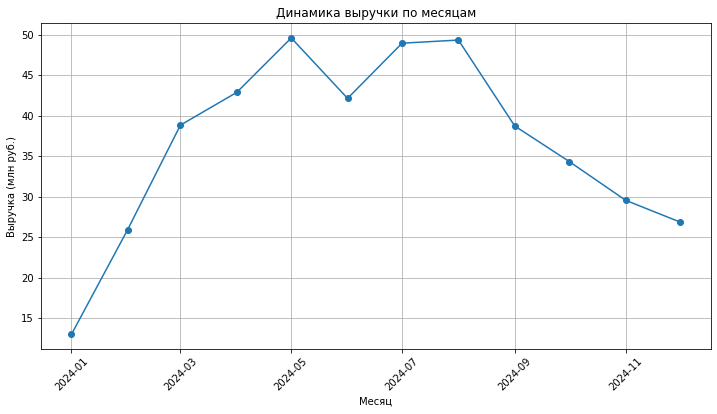

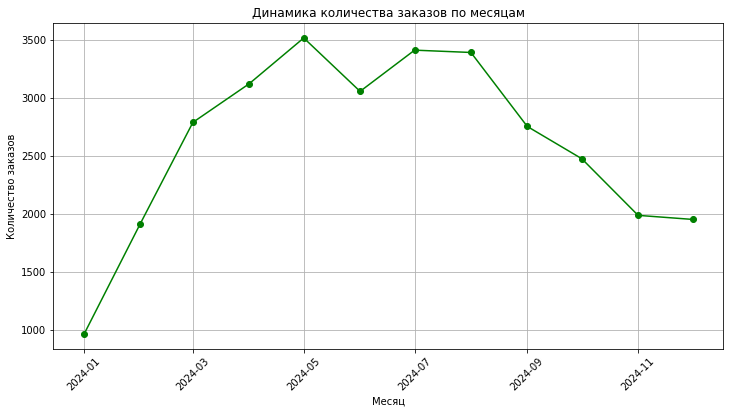

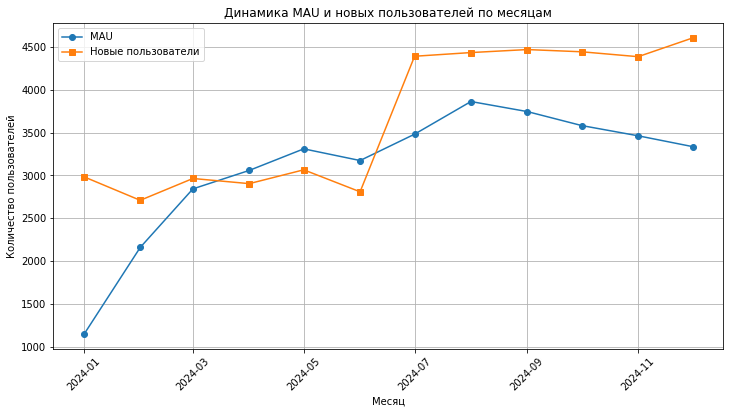

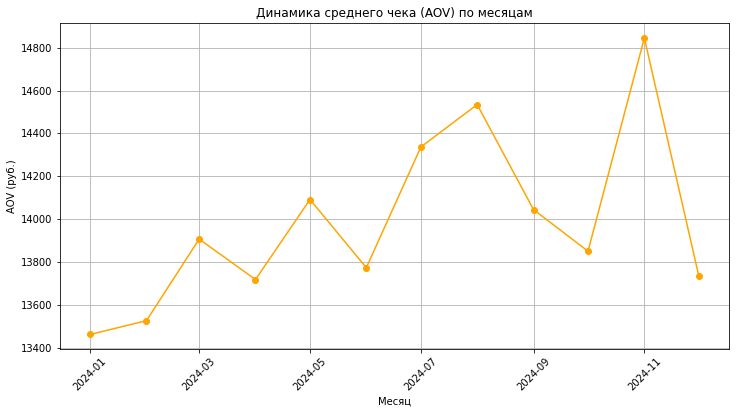

In [7]:
#Групировка заказов по месяцам
monthly_orders = orders.groupby('order_month').agg({
    'order_id': 'count',
    'user_id': 'nunique',
    'total_price': 'sum'
}).reset_index()

monthly_orders.columns = ['month', 'orders_count', 'buyers_count', 'revenue']

#AOV
monthly_orders['aov'] = monthly_orders['revenue'] / monthly_orders['orders_count']

#MAU
mau = events.groupby('event_month')['user_id'].nunique().reset_index()
mau.columns = ['month', 'mau']

#Новые пользователи по месяцам
new_users = users.groupby('cohort_month')['user_id'].nunique().reset_index()
new_users.columns = ['month', 'new_users']

# Слияние всех метрик по месяцу
metrics = monthly_orders.merge(mau, on='month', how='left')
metrics = metrics.merge(new_users, on='month', how='left')

display(metrics)

#Визуализации

# Выручка по месяцам
plt.figure(figsize=(12, 6))
plt.plot(metrics['month'], metrics['revenue'] / 1000000, marker='o')
plt.title('Динамика выручки по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Выручка (млн руб.)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# Количество заказов по месяцам
plt.figure(figsize=(12, 6))
plt.plot(metrics['month'], metrics['orders_count'], marker='o', color='green')
plt.title('Динамика количества заказов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество заказов')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# MAU и новые пользователи
plt.figure(figsize=(12, 6))
plt.plot(metrics['month'], metrics['mau'], marker='o', label='MAU')
plt.plot(metrics['month'], metrics['new_users'], marker='s', label='Новые пользователи')
plt.title('Динамика MAU и новых пользователей по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество пользователей')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# AOV по месяцам
plt.figure(figsize=(12, 6))
plt.plot(metrics['month'], metrics['aov'], marker='o', color='orange')
plt.title('Динамика среднего чека (AOV) по месяцам')
plt.xlabel('Месяц')
plt.ylabel('AOV (руб.)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [8]:
# DAU
dau = events.groupby(events['event_date'].dt.date)['user_id'].nunique()

print("DAU статистика")
print(f"Средний DAU: {dau.mean():.0f}")
print(f"Медианный DAU: {dau.median():.0f}")
print(f"Минимальный DAU: {dau.min():.0f}")
print(f"Максимальный DAU: {dau.max():.0f}")
print(f"Стандартное отклонение: {dau.std():.0f}")

# WAU
wau = events.groupby('event_week')['user_id'].nunique()

print("\nWAU статистика")
print(f"Средний WAU: {wau.mean():.0f}")
print(f"Медианный WAU: {wau.median():.0f}")
print(f"Минимальный WAU: {wau.min():.0f}")
print(f"Максимальный WAU: {wau.max():.0f}")
print(f"Стандартное отклонение: {wau.std():.0f}")

# MAU
mau = events.groupby('event_month')['user_id'].nunique()

print("\nMAU статистика")
print(f"Средний MAU: {mau.mean():.0f}")
print(f"Медианный MAU: {mau.median():.0f}")
print(f"Минимальный MAU: {mau.min():.0f}")
print(f"Максимальный MAU: {mau.max():.0f}")
print(f"Стандартное отклонение: {mau.std():.0f}")

print("\nСоотношение метрик активности")
print(f"WAU / MAU: {wau.mean() / mau.mean():.2f}")
print(f"DAU / MAU: {dau.mean() / mau.mean():.2f}")
print(f"DAU / WAU: {dau.mean() / wau.mean():.2f}")

DAU статистика
Средний DAU: 306
Медианный DAU: 318
Минимальный DAU: 5
Максимальный DAU: 473
Стандартное отклонение: 83

WAU статистика
Средний WAU: 1173
Медианный WAU: 1258
Минимальный WAU: 133
Максимальный WAU: 1494
Стандартное отклонение: 306

MAU статистика
Средний MAU: 3097
Медианный MAU: 3323
Минимальный MAU: 1149
Максимальный MAU: 3861
Стандартное отклонение: 760

Соотношение метрик активности
WAU / MAU: 0.38
DAU / MAU: 0.10
DAU / WAU: 0.26


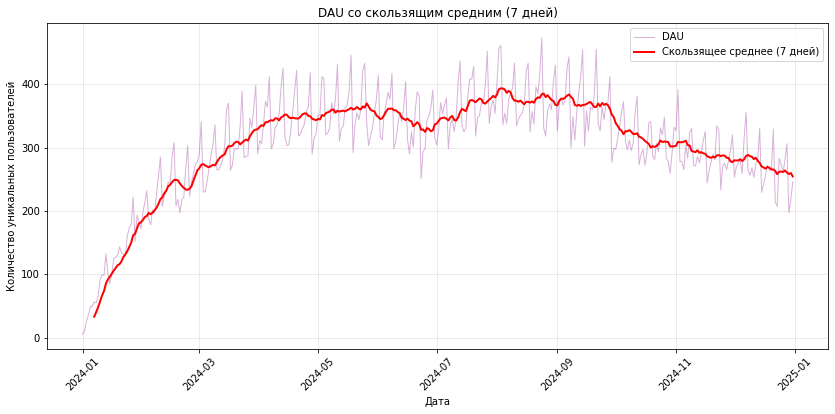

In [9]:
plt.figure(figsize=(14, 6))
plt.plot(dau.index, dau.values, color='purple', alpha=0.3, linewidth=1, label='DAU')
plt.plot(dau.index, dau.rolling(7).mean(), color='red', linewidth=2, label='Скользящее среднее (7 дней)')
plt.title('DAU со скользящим средним (7 дней)')
plt.xlabel('Дата')
plt.ylabel('Количество уникальных пользователей')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

,step,users,conversion_from_first_%,conversion_from_previous_%
0,product_view,22069,100.0,NaN
1,add_to_cart,20411,92.5,92.5
2,checkout_start,16769,76.0,82.2
3,checkout_complete,13897,63.0,82.9
4,orders,8922,40.4,64.2


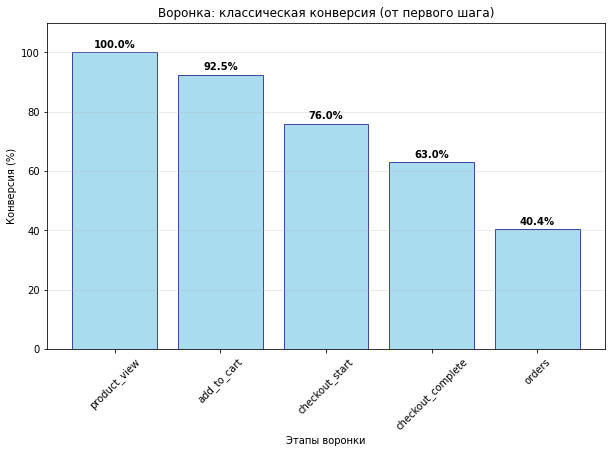

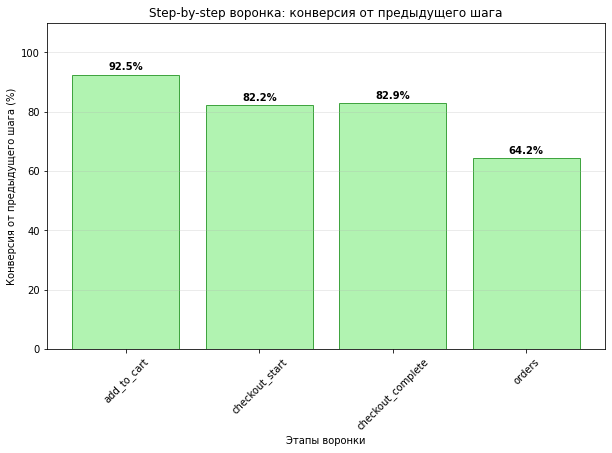

In [10]:
funnel_steps = ['product_view', 'add_to_cart', 'checkout_start', 'checkout_complete']

# Считаем количество уникальных пользователей на каждом шаге
funnel_counts = events.groupby('event_type')['user_id'].nunique().reindex(funnel_steps)

# Добавляем фактические покупки
orders_users = orders['user_id'].nunique()

# Создаём список шагов и пользователей
steps_list = list(funnel_counts.index) + ['orders']
users_list = list(funnel_counts.values) + [orders_users]

# Создаём DataFrame
funnel_events_data = pd.DataFrame({
    'step': steps_list,
    'users': users_list
})

# Берём количество пользователей на первом шаге
first_step_users = funnel_events_data['users'].iloc[0]

# Конверсия от первого шага
funnel_events_data['conversion_from_first_%'] = (funnel_events_data['users'] / first_step_users * 100).round(1)

# Конверсия от предыдущего шага
funnel_events_data['conversion_from_previous_%'] = (funnel_events_data['users'] / funnel_events_data['users'].shift(1) * 100).round(1)

display(funnel_events_data)

# Визуализация классической воронки
plt.figure(figsize=(10, 6))
steps_for_plot = funnel_events_data['step']
conversions = funnel_events_data['conversion_from_first_%']

plt.bar(steps_for_plot, conversions, color='skyblue', edgecolor='navy', alpha=0.7)

for i, (step, conv) in enumerate(zip(steps_for_plot, conversions)):
    plt.text(i, conv + 1, f'{conv:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Воронка: классическая конверсия (от первого шага)')
plt.ylabel('Конверсия (%)')
plt.xlabel('Этапы воронки')
plt.xticks(rotation=45)
plt.ylim(0, 110)
plt.grid(axis='y', alpha=0.3)
plt.show()

# Визуализация Step-by-step воронки
plt.figure(figsize=(10, 6))
steps_for_plot = funnel_events_data['step'].iloc[1:]
conversions = funnel_events_data['conversion_from_previous_%'].iloc[1:]

plt.bar(steps_for_plot, conversions, color='lightgreen', edgecolor='green', alpha=0.7)

for i, (step, conv) in enumerate(zip(steps_for_plot, conversions)):
    plt.text(i, conv + 1, f'{conv:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Step-by-step воронка: конверсия от предыдущего шага')
plt.ylabel('Конверсия от предыдущего шага (%)')
plt.xlabel('Этапы воронки')
plt.xticks(rotation=45)
plt.ylim(0, 110)
plt.grid(axis='y', alpha=0.3)
plt.show()

month_diff,0,1,2,3,4,5,6,7,8,9,10
registration_month,,,,,,,,,,,
2024-01,14.706868,14.271357,7.470687,3.785595,1.742044,0.737018,0.536013,0.268007,0.033501,0.033501,0.033501
2024-02,13.943194,16.709701,8.041313,3.799336,1.733678,0.811509,0.184434,0.221321,0.000000,0.000000,0.000000
2024-03,15.244519,16.188870,8.195616,3.608769,1.956155,1.045531,0.505902,0.134907,0.033727,0.000000,0.000000
2024-04,16.385542,17.211704,7.986231,3.511188,1.858864,1.067126,0.585198,0.172117,0.206540,0.000000,0.000000
2024-05,15.133725,14.872798,7.045010,3.424658,1.043705,0.521853,0.293542,0.097847,0.000000,0.000000,0.000000
2024-06,11.992883,15.017794,6.548043,2.562278,1.494662,0.320285,0.213523,0.000000,0.000000,0.000000,0.000000
2024-07,11.690975,12.010027,5.059253,2.552416,1.048314,0.524157,0.000000,0.000000,0.000000,0.000000,0.000000
2024-08,9.794629,9.004739,4.242835,2.121417,0.677048,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2024-09,8.060905,7.277206,3.425884,1.746529,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


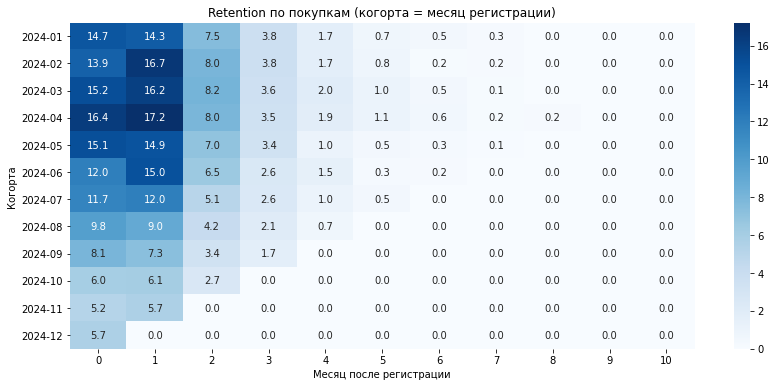

In [11]:
users['cohort_month'] = users['cohort_month'].dt.to_period('M')
orders['order_month'] = orders['order_month'].dt.to_period('M')

users_cohort = users[['user_id', 'cohort_month']]
users_cohort.columns = ['user_id', 'registration_month']

orders_cohort = orders[['user_id', 'order_month']]

# Соединяем
orders_with_reg = orders_cohort.merge(users_cohort, on='user_id', how='left')

# Считаем разницу месяцев
orders_with_reg['month_diff'] = (orders_with_reg['order_month'].astype(int) - orders_with_reg['registration_month'].astype(int))

# Убираем покупки до регистрации
orders_with_reg = orders_with_reg[orders_with_reg['month_diff'] >= 0]

# Retention-матрица
retention = orders_with_reg.pivot_table(
    index='registration_month',
    columns='month_diff',
    values='user_id',
    aggfunc='nunique',
    fill_value=0
)

# Размеры когорт
cohort_sizes = users.groupby('cohort_month')['user_id'].nunique()

# Retention rate
retention_rate = retention.div(cohort_sizes, axis=0) * 100

display(retention_rate)

# Визуализация
plt.figure(figsize=(14, 6))
sns.heatmap(retention_rate, annot=True, fmt=".1f", cmap="Blues")
plt.title("Retention по покупкам (когорта = месяц регистрации)")
plt.xlabel("Месяц после регистрации")
plt.ylabel("Когорта")
plt.show()

month_diff,0,1,2,3,4,5,6,7,8,9,10,11
registration_month,,,,,,,,,,,,
2024-01,36.917923,36.917923,17.721943,8.174204,4.120603,1.842546,0.871022,0.402010,0.033501,0.067002,0.033501,0.033501
2024-02,36.038362,40.501660,17.890077,9.037256,4.721505,1.844338,0.885282,0.368868,0.110660,0.036887,0.073774,0.000000
2024-03,37.976391,37.605396,19.156830,9.274874,4.283305,2.091062,0.809444,0.269815,0.067454,0.067454,0.000000,0.000000
2024-04,38.450947,39.311532,19.380379,9.363167,4.819277,2.271945,1.067126,0.688468,0.309811,0.000000,0.000000,0.000000
2024-05,37.247228,36.921070,17.188519,7.729941,3.620352,1.630789,0.456621,0.228311,0.000000,0.000000,0.000000,0.000000
2024-06,33.487544,34.306050,17.010676,7.615658,3.772242,1.779359,0.533808,0.000000,0.000000,0.000000,0.000000,0.000000
2024-07,31.996354,32.748405,14.881495,7.087511,3.555150,1.276208,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2024-08,31.099075,30.173776,14.195441,7.447529,3.272399,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2024-09,27.541424,28.526646,13.949843,5.709807,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


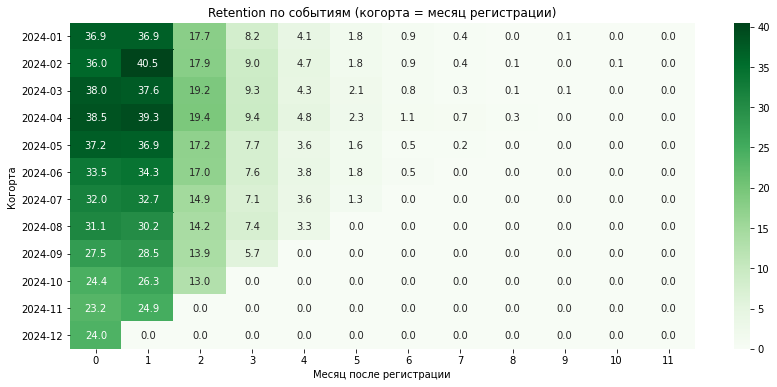

In [12]:
events['event_month'] = events['event_month'].dt.to_period('M')

users_cohort = users[['user_id', 'cohort_month']]
users_cohort.columns = ['user_id', 'registration_month']

events_cohort = events[['user_id', 'event_month']]

# Соединяем
events_with_reg = events_cohort.merge(users_cohort, on='user_id', how='left')

# Считаем разницу месяцев
events_with_reg['month_diff'] = (events_with_reg['event_month'].astype(int) - events_with_reg['registration_month'].astype(int))

# Убираем события до регистрации
events_with_reg = events_with_reg[events_with_reg['month_diff'] >= 0]

# Строим retention-матрицу
retention_events = events_with_reg.pivot_table(
    index='registration_month',
    columns='month_diff',
    values='user_id',
    aggfunc='nunique',
    fill_value=0
)

# Размеры когорт
cohort_sizes = users.groupby('cohort_month')['user_id'].nunique()

# Retention rate по событиям
retention_events_rate = retention_events.div(cohort_sizes, axis=0) * 100

display(retention_events_rate)

# Визуализация
plt.figure(figsize=(14, 6))
sns.heatmap(retention_events_rate, annot=True, fmt=".1f", cmap="Greens")
plt.title("Retention по событиям (когорта = месяц регистрации)")
plt.xlabel("Месяц после регистрации")
plt.ylabel("Когорта")
plt.show()

#### Выводы по этапу 2:

*Общие показатели:*
- Всего пользователей: 44 151
- Всего заказов: 31 357
- Платящих пользователей: 8 922 (доля платящих — 20.2%)
- Общая выручка бизнеса (5% комиссии): 22.0 млн руб.
- Средний чек (AOV): 14 030 руб.

*Динамика:*
- Рост в первой половине года: выручка выросла с 13 млн руб. в январе до 49.6 млн руб. в мае (+280%)
- Спад во второй половине: с мая по декабрь выручка снизилась на 46%
- AOV стабильно растет: с 13 462 руб. до 14 845 руб. (+10% за год)

*Активность пользователей:*
- Средний DAU: 306 пользователей/день
- Средний WAU: 1 173 пользователей/неделю
- Средний MAU: 3 097 пользователей/месяц
- Соотношения: WAU/MAU = 0.38, DAU/MAU = 0.10

*Тревожные сигналы:*
- Сильное падение во второй половине года — требует анализа причин
- Retention падает до 3% к 3-му месяцу — проблема удержания пользователей
- 36% потерь на этапе оплаты (checkout_complete - purchase)

**Вывод:** Продукт демонстрирует хорошие показатели монетизации и вовлеченности, но требует работы над удержанием и конверсией на финальных этапах воронки.

### 3. Оценка метрик монетизации и юнит-экономики

Выполните анализ монетизации. Определите, сколько зарабатывает продукт и сколько тратит на привлечение.

Важны как агрегированные метрики (ARPU, AOV), так и показатели эффективности (CAC, ROI, Payback Period).

Сформулируйте первые выводы по результатам анализа метрик. Сделайте это в формате записки для заказчика. Изложите все основные результаты так, чтобы прослеживалась связь между мыслями. Не пишите много — заказчик не будет читать записку полностью, а просто просмотрит.

Напишите выводы в конце блока, чтобы заказчик мог быстро ознакомиться с основными результатами.

In [13]:
# Общие цифры
total_users = users['user_id'].nunique()
total_orders = orders['order_id'].nunique()
total_revenue_before_commission = orders['total_price'].sum()  # до комиссии
total_revenue = total_revenue_before_commission * 0.05  # 5% комиссии
paying_users = orders['user_id'].nunique()

# Средние метрики
aov = total_revenue_before_commission / total_orders
arpu = total_revenue / total_users
arppu = total_revenue / paying_users

print(f"Общее количество пользователей: {total_users:,}")
print(f"Общее количество заказов: {total_orders:,}")
print(f"Общая прибыль: {total_revenue_before_commission:,.0f} руб.")
print(f"Общая выручка (5% комиссии): {total_revenue:,.0f} руб.")
print(f"Количество платящих пользователей: {paying_users:,}")
print(f"\nAOV (средний чек): {aov:,.0f} руб.")
print(f"ARPU (доход на пользователя): {arpu:,.0f} руб.")
print(f"ARPPU (доход на платящего): {arppu:,.0f} руб.")

Общее количество пользователей: 44,151
Общее количество заказов: 31,357
Общая прибыль: 439,944,215 руб.
Общая выручка (5% комиссии): 21,997,211 руб.
Количество платящих пользователей: 8,922

AOV (средний чек): 14,030 руб.
ARPU (доход на пользователя): 498 руб.
ARPPU (доход на платящего): 2,466 руб.


,acq_channel,new_users,total_spend_formated,cac_formated
3,SEO,3312,"661,512 руб.",200 руб.
1,Email Marketing,2044,"538,342 руб.",263 руб.
0,Affiliate,6069,"2,012,341 руб.",332 руб.
4,Social Media,4179,"1,647,396 руб.",394 руб.
2,Google Ads,9319,"4,663,490 руб.",500 руб.
5,TikTok,19228,"9,695,376 руб.",504 руб.


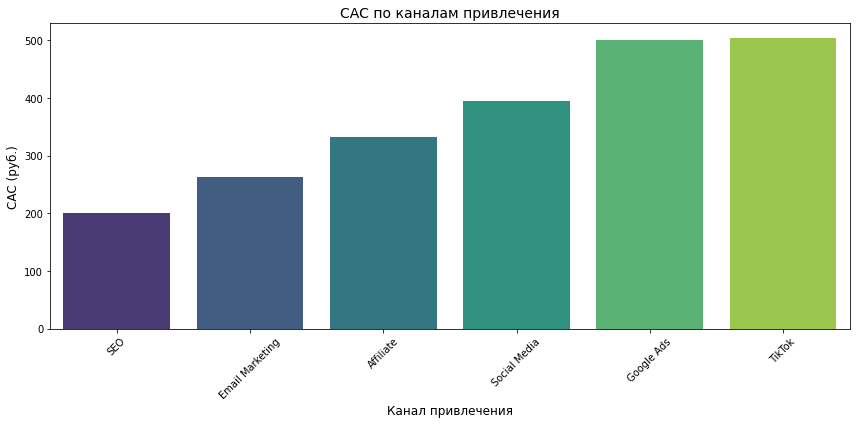

In [14]:
# Новые пользователи по каналам
new_users_by_channel = users.groupby('acq_channel')['user_id'].nunique().reset_index()
new_users_by_channel.columns = ['acq_channel', 'new_users']

# Общие затраты по каналам
total_spend_by_channel = campaign_costs.groupby('acq_channel')['budget'].sum().reset_index()
total_spend_by_channel.columns = ['acq_channel', 'total_spend']

# Объединяем
cac_data = new_users_by_channel.merge(total_spend_by_channel, on='acq_channel', how='left')
cac_data['cac'] = cac_data['total_spend'] / cac_data['new_users']

# Форматируем для читаемости
cac_data['total_spend_formated'] = cac_data['total_spend'].apply(lambda x: f"{x:,.0f} руб.")
cac_data['cac_formated'] = cac_data['cac'].apply(lambda x: f"{x:,.0f} руб.")

# Сортируем по CAC
cac_data_sorted = cac_data.sort_values('cac', ascending=True)

display(cac_data_sorted[['acq_channel', 'new_users', 'total_spend_formated', 'cac_formated']])

# Визуализация
plt.figure(figsize=(12, 6))
sns.barplot(data=cac_data_sorted, x='acq_channel', y='cac', palette='viridis')
plt.title('CAC по каналам привлечения', fontsize=14)
plt.xlabel('Канал привлечения', fontsize=12)
plt.ylabel('CAC (руб.)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Среднее количество заказов на платящего пользователя: 3.51
LTV (простой): 8,665 руб.


,acq_channel,users,total_revenue_formated,revenue_formated,arppu_formated,ltv_formated
0,Affiliate,6069,"134,716,296 руб.","6,735,815 руб.","1,110 руб.","3,901 руб."
1,Email Marketing,2044,"11,113,975 руб.","555,699 руб.",272 руб.,956 руб.
2,Google Ads,9319,"164,735,205 руб.","8,236,760 руб.",884 руб.,"3,106 руб."
3,SEO,3312,"38,198,695 руб.","1,909,935 руб.",577 руб.,"2,027 руб."
4,Social Media,4179,"60,005,095 руб.","3,000,255 руб.",718 руб.,"2,523 руб."
5,TikTok,19228,"18,208,964 руб.","910,448 руб.",47 руб.,166 руб.


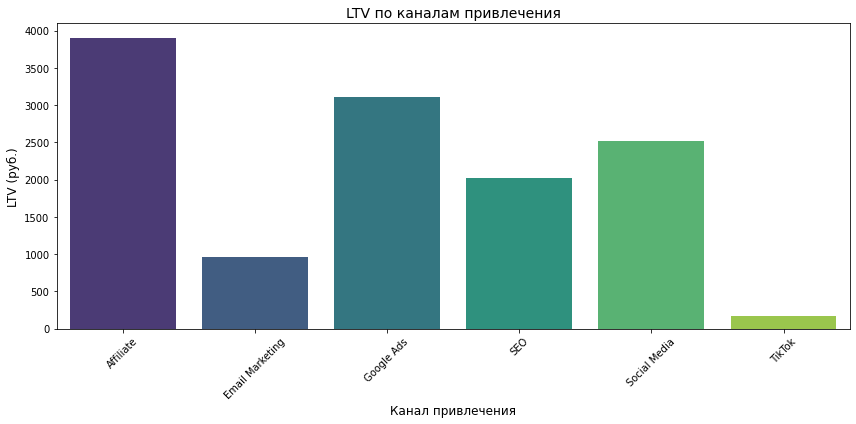

In [15]:
# LTV
avg_orders_per_user = total_orders / paying_users
ltv_simple = arppu * avg_orders_per_user

print(f"Среднее количество заказов на платящего пользователя: {avg_orders_per_user:.2f}")
print(f"LTV (простой): {ltv_simple:,.0f} руб.")

# LTV по каналам
channel_ltv = users.merge(orders, on='user_id', how='left')
channel_ltv = channel_ltv.groupby('acq_channel').agg({
    'user_id': 'nunique',
    'total_price': 'sum'
}).reset_index()
channel_ltv.columns = ['acq_channel', 'users', 'total_revenue']
channel_ltv['revenue'] = channel_ltv['total_revenue'] * 0.05
channel_ltv['arppu'] = channel_ltv['revenue'] / channel_ltv['users']
channel_ltv['ltv'] = channel_ltv['arppu'] * avg_orders_per_user
channel_ltv['total_revenue_formated'] = channel_ltv['total_revenue'].apply(lambda x: f"{x:,.0f} руб.")
channel_ltv['revenue_formated'] = channel_ltv['revenue'].apply(lambda x: f"{x:,.0f} руб.")
channel_ltv['arppu_formated'] = channel_ltv['arppu'].apply(lambda x: f"{x:,.0f} руб.")
channel_ltv['ltv_formated'] = channel_ltv['ltv'].apply(lambda x: f"{x:,.0f} руб.")

display(channel_ltv[['acq_channel', 'users', 'total_revenue_formated', 'revenue_formated', 'arppu_formated', 'ltv_formated']])

# Визуализация
plt.figure(figsize=(12, 6))
sns.barplot(data=channel_ltv, x='acq_channel', y='ltv', palette='viridis')
plt.title('LTV по каналам привлечения', fontsize=14)
plt.xlabel('Канал привлечения', fontsize=12)
plt.ylabel('LTV (руб.)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,acq_channel,cac_formated,ltv_formated,roi_formated,payback_period_formated
0,Affiliate,332 руб.,"3,901 руб.",1076%,1.0 мес.
1,Email Marketing,263 руб.,956 руб.,263%,3.3 мес.
2,Google Ads,500 руб.,"3,106 руб.",521%,1.9 мес.
3,SEO,200 руб.,"2,027 руб.",915%,1.2 мес.
4,Social Media,394 руб.,"2,523 руб.",540%,1.9 мес.
5,TikTok,504 руб.,166 руб.,-67%,36.4 мес.


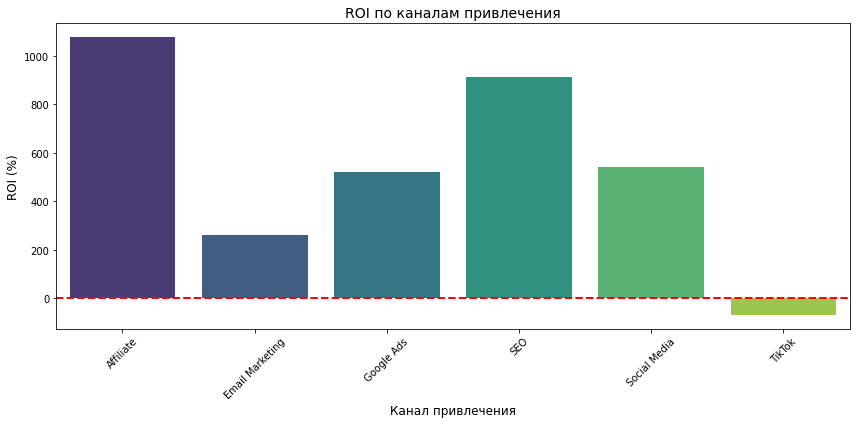

In [16]:
# Объединяем CAC и LTV
roi_data = cac_data.merge(channel_ltv[['acq_channel', 'ltv']], on='acq_channel', how='left')

# Расчет ROI
roi_data['roi'] = (roi_data['ltv'] - roi_data['cac']) / roi_data['cac'] * 100

# Payback Period (месяцев)
roi_data['payback_period'] = roi_data['cac'] / (roi_data['ltv'] / 12)

# Форматируем для читаемости
roi_data['cac_formated'] = roi_data['cac'].apply(lambda x: f"{x:,.0f} руб.")
roi_data['ltv_formated'] = roi_data['ltv'].apply(lambda x: f"{x:,.0f} руб.")
roi_data['roi_formated'] = roi_data['roi'].apply(lambda x: f"{x:.0f}%")
roi_data['payback_period_formated'] = roi_data['payback_period'].apply(lambda x: f"{x:.1f} мес.")

display(roi_data[['acq_channel', 'cac_formated', 'ltv_formated', 'roi_formated', 'payback_period_formated']])

# Визуализация
plt.figure(figsize=(12, 6))
sns.barplot(data=roi_data, x='acq_channel', y='roi', palette='viridis')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.title('ROI по каналам привлечения', fontsize=14)
plt.xlabel('Канал привлечения', fontsize=12)
plt.ylabel('ROI (%)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Выводы по этапу 3:

*Ключевые метрики:*
- AOV (средний чек): 14 030 руб.
- ARPU (доход на пользователя): 498 руб.
- ARPPU (доход на платящего): 2 466 руб.
- LTV (пожизненная ценность клиента): 8 665 руб.

*Эффективность каналов привлечения:*

In [17]:
roi_display = roi_data[['acq_channel', 'cac_formated', 'ltv_formated', 'roi_formated', 'payback_period_formated']].rename(columns={
    'acq_channel': 'Канал',
    'cac_formated': 'CAC',
    'ltv_formated': 'LTV',
    'roi_formated': 'ROI',
    'payback_period_formated': 'Окупаемость'
})

display(roi_display)

,Канал,CAC,LTV,ROI,Окупаемость
0,Affiliate,332 руб.,"3,901 руб.",1076%,1.0 мес.
1,Email Marketing,263 руб.,956 руб.,263%,3.3 мес.
2,Google Ads,500 руб.,"3,106 руб.",521%,1.9 мес.
3,SEO,200 руб.,"2,027 руб.",915%,1.2 мес.
4,Social Media,394 руб.,"2,523 руб.",540%,1.9 мес.
5,TikTok,504 руб.,166 руб.,-67%,36.4 мес.


*Ключевые выводы:*
- Лучшие каналы — Affiliate и SEO. Они дают максимальную отдачу (ROI > 900%) и окупаются за 1 месяц.
- TikTok — убыточный канал. CAC (504 руб.) в 3 раза выше LTV (166 руб.). Рекомендуем пересмотреть таргетинг или сократить бюджет.
- Email Marketing — слабое место на этапе оплаты. Конверсия checkout→purchase всего 36.6% против средних 60.4%.
- Общий LTV (8 665 руб.) значительно выше CAC большинства каналов — экономика продукта в целом здорова.

## Выводы по этапам 2 и 3


Представьте ключевые выводы в текстовом виде здесь или приложите ссылку на документ с презентацией.

Не забудьте предоставить доступ на просмотр и комментирование документа.

**Обзор ключевых метрик (Этап 2)**

*Продукт демонстрирует здоровые показатели:*
- Доля платящих пользователей 20.2%
- AOV 14 030 руб. — высокий средний чек
- AOV растет на протяжении года (+10%)
- Вовлеченность: DAU/MAU = 0.10, WAU/MAU = 0.38 — хорошие показатели

*Основные проблемы:*
- Сезонное падение во второй половине года (выручка упала на 46% с мая по декабрь)
- Удержание падает до 3% к 3-му месяцу — клиенты не совершают повторные покупки
- 36% потерь на этапе оплаты

**Монетизация и юнит-экономика (Этап 3)**

*Экономика продукта в целом здорова:*
- LTV = 8 665 руб. — значительно выше CAC большинства каналов
- ARPU = 498 руб., ARPPU = 2 466 руб.

*Каналы привлечения:*
- Affiliate и SEO — лучшие каналы (ROI > 900%, окупаемость ~1 месяц)
- TikTok — единственный убыточный канал (ROI -67%)
- Email Marketing — требует улучшения конверсии на этапе оплаты

*Ключевые точки роста:*
- Оптимизация этапа оплаты (повышение конверсии checkout→purchase)
- Улучшение удержания в первые 3 месяца после регистрации
- Пересмотр стратегии в TikTok
- Увеличение инвестиций в Affiliate и SEO

## 4. Поиск инсайтов, точек роста и сегментация


In [18]:
# Базовые метрики по каналам
channel_metrics = users.merge(orders, on='user_id', how='left')

# Количество пользователей по каналам
channel_users = users.groupby('acq_channel')['user_id'].nunique().reset_index()
channel_users.columns = ['acq_channel', 'total_users']

# Количество покупателей по каналам
users_with_orders = channel_metrics[channel_metrics['order_id'].notna()]
channel_buyers = users_with_orders.groupby('acq_channel')['user_id'].nunique().reset_index()
channel_buyers.columns = ['acq_channel', 'buyers']

# Количество заказов по каналам
channel_orders = channel_metrics.groupby('acq_channel')['order_id'].count().reset_index()
channel_orders.columns = ['acq_channel', 'total_orders']

# AOV по каналам
channel_aov = channel_metrics.groupby('acq_channel')['total_price'].sum().reset_index()
channel_aov.columns = ['acq_channel', 'total_revenue']
channel_aov = channel_aov.merge(channel_orders, on='acq_channel')
channel_aov['aov'] = (channel_aov['total_revenue'] / channel_aov['total_orders']).round(0)

# Конверсия (покупатели / все пользователи)
channel_conversion = channel_users.merge(channel_buyers, on='acq_channel', how='left')
channel_conversion['buyers'] = channel_conversion['buyers'].fillna(0)
channel_conversion['conversion_rate'] = (channel_conversion['buyers'] / channel_conversion['total_users'] * 100).round(1)

# Объединяем
channel_summary = channel_conversion.merge(channel_aov[['acq_channel', 'aov']], on='acq_channel')
channel_summary = channel_summary.merge(channel_orders, on='acq_channel')
channel_summary = channel_summary.merge(cac_data[['acq_channel', 'cac']], on='acq_channel')
channel_summary = channel_summary.merge(channel_ltv[['acq_channel', 'ltv']], on='acq_channel', how='left')

# ROI
channel_summary['roi'] = ((channel_summary['ltv'] - channel_summary['cac']) / channel_summary['cac'] * 100).round(0)

# Форматирование
channel_summary['cac_formated'] = channel_summary['cac'].apply(lambda x: f"{x:,.0f} руб.")
channel_summary['ltv_formated'] = channel_summary['ltv'].apply(lambda x: f"{x:,.0f} руб.")
channel_summary['roi_formated'] = channel_summary['roi'].apply(lambda x: f"{x:.0f}%")
channel_summary['aov_formated'] = channel_summary['aov'].apply(lambda x: f"{x:,.0f} руб.")

print("Метрики по каналам привлечения")
display(channel_summary[['acq_channel', 'total_users', 'buyers', 'total_orders', 'conversion_rate', 'aov_formated', 'cac_formated', 'ltv_formated', 'roi_formated']])

Метрики по каналам привлечения


,acq_channel,total_users,buyers,total_orders,conversion_rate,aov_formated,cac_formated,ltv_formated,roi_formated
0,Affiliate,6069,2338,9668,38.5,"13,934 руб.",332 руб.,"3,901 руб.",1076%
1,Email Marketing,2044,325,793,15.9,"14,015 руб.",263 руб.,956 руб.,263%
2,Google Ads,9319,3187,11896,34.2,"13,848 руб.",500 руб.,"3,106 руб.",521%
3,SEO,3312,874,2803,26.4,"13,628 руб.",200 руб.,"2,027 руб.",915%
4,Social Media,4179,1211,3978,29.0,"15,084 руб.",394 руб.,"2,523 руб.",540%
5,TikTok,19228,719,1308,3.7,"13,921 руб.",504 руб.,166 руб.,-67%


Метрики по регионам


,region,total_users,buyers,total_orders,conversion_rate,aov_formated,total_revenue_formated,revenue_per_user_formated
0,Другие регионы,14516,2816,9807,19.4,"13,944 руб.","136,747,226 руб.","9,420 руб."
3,Москва,10959,2200,7949,20.1,"13,612 руб.","108,203,683 руб.","9,873 руб."
8,Санкт-Петербург,6690,1317,4667,19.7,"14,554 руб.","67,925,851 руб.","10,153 руб."
4,Московская область,3549,681,2280,19.2,"14,549 руб.","33,172,280 руб.","9,347 руб."
1,Екатеринбург,2145,418,1592,19.5,"14,369 руб.","22,875,318 руб.","10,664 руб."
5,Нижний Новгород,1748,354,1224,20.3,"13,749 руб.","16,828,440 руб.","9,627 руб."
2,Краснодар,1398,290,949,20.7,"15,360 руб.","14,576,753 руб.","10,427 руб."
6,Новосибирск,1723,310,1072,18.0,"13,596 руб.","14,574,581 руб.","8,459 руб."
7,Ростов-на-Дону,1423,268,906,18.8,"13,327 руб.","12,074,096 руб.","8,485 руб."


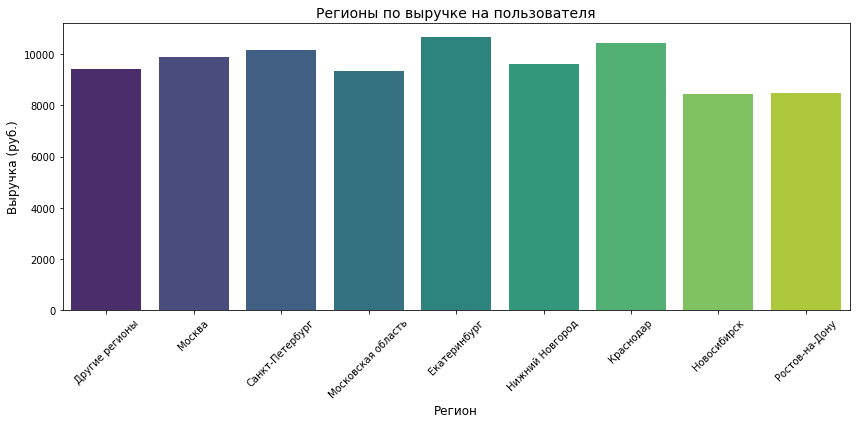

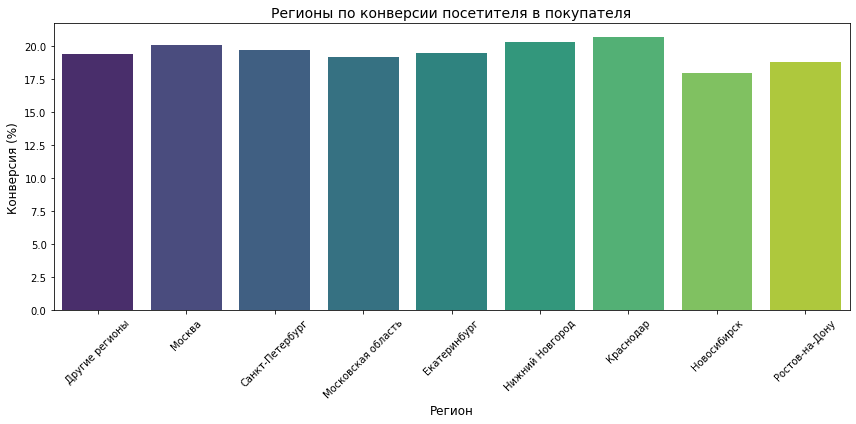

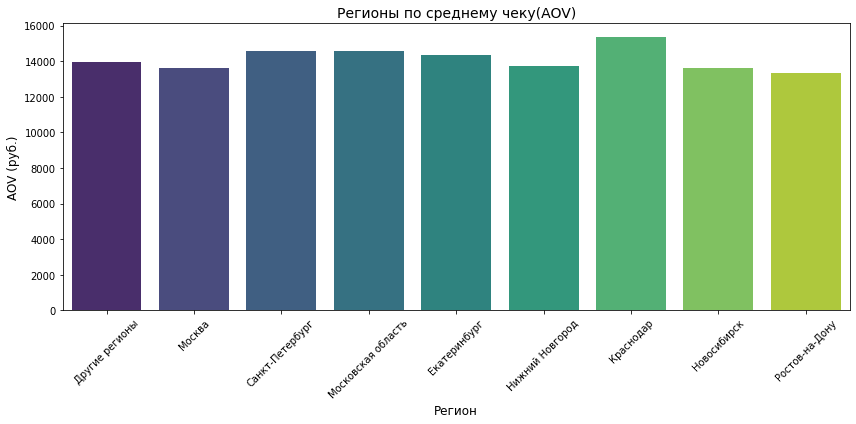

In [19]:
# Объединяем пользователей и заказы
region_metrics = users.merge(orders, on='user_id', how='left')

# Общая статистика по регионам
region_summary = region_metrics.groupby('region').agg({
    'user_id': 'nunique',
    'order_id': 'count',
    'total_price': 'sum'
}).reset_index()

region_summary.columns = ['region', 'total_users', 'total_orders', 'total_revenue']

# Количество покупателей
region_buyers = region_metrics[region_metrics['order_id'].notna()].groupby('region')['user_id'].nunique().reset_index()
region_buyers.columns = ['region', 'buyers']

# Объединяем
region_summary = region_summary.merge(region_buyers, on='region', how='left')
region_summary['buyers'] = region_summary['buyers'].fillna(0)

# Расчет метрик
region_summary['conversion_rate'] = (region_summary['buyers'] / region_summary['total_users'] * 100).round(1)
region_summary['aov'] = (region_summary['total_revenue'] / region_summary['total_orders']).round(0)
region_summary['revenue_per_user'] = (region_summary['total_revenue'] / region_summary['total_users']).round(0)

# Сортируем по выручке
region_summary_sorted = region_summary.sort_values('total_revenue', ascending=False)

# Форматирование
region_summary_sorted['total_revenue_formated'] = region_summary_sorted['total_revenue'].apply(lambda x: f"{x:,.0f} руб.")
region_summary_sorted['aov_formated'] = region_summary_sorted['aov'].apply(lambda x: f"{x:,.0f} руб.")
region_summary_sorted['revenue_per_user_formated'] = region_summary_sorted['revenue_per_user'].apply(lambda x: f"{x:,.0f} руб.")

print("Метрики по регионам")
display(region_summary_sorted[['region', 'total_users', 'buyers', 'total_orders', 'conversion_rate', 'aov_formated', 'total_revenue_formated', 'revenue_per_user_formated']])

# Визуализации
plt.figure(figsize=(12, 6))
top_regions = region_summary_sorted
sns.barplot(data=top_regions, x='region', y='revenue_per_user', palette='viridis')
plt.title('Регионы по выручке на пользователя', fontsize=14)
plt.xlabel('Регион', fontsize=12)
plt.ylabel('Выручка (руб.)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
top_regions = region_summary_sorted
sns.barplot(data=top_regions, x='region', y='conversion_rate', palette='viridis')
plt.title('Регионы по конверсии посетителя в покупателя', fontsize=14)
plt.xlabel('Регион', fontsize=12)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
top_regions = region_summary_sorted
sns.barplot(data=top_regions, x='region', y='aov', palette='viridis')
plt.title('Регионы по среднему чеку(AOV)', fontsize=14)
plt.xlabel('Регион', fontsize=12)
plt.ylabel('AOV (руб.)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Метрики по устройствам


,device,users,buyers,revenue_formated,conversion_rate,aov_formated
0,desktop,7447,2428,"130,945,046 руб.",32.6,"53,931 руб."
1,mobile,7431,2493,"133,572,856 руб.",33.5,"53,579 руб."
2,tablet,7260,2377,"135,905,005 руб.",32.7,"57,175 руб."


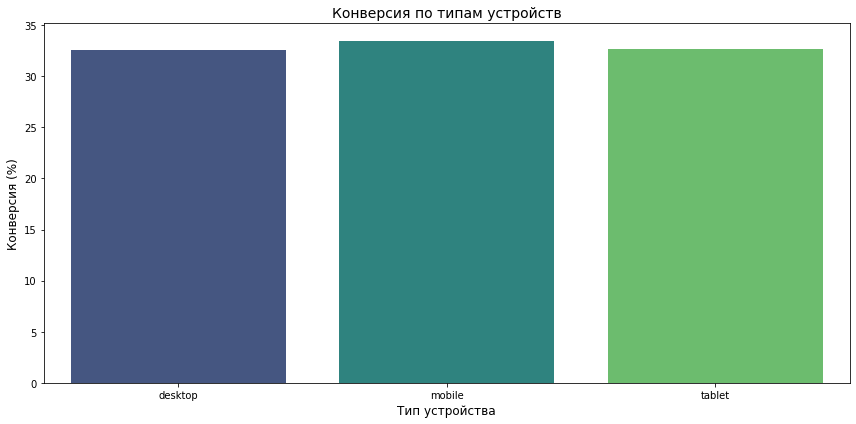

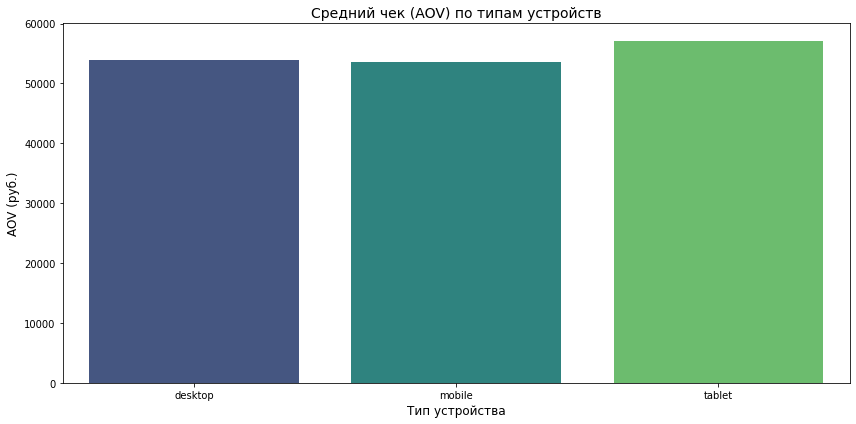

In [20]:
# Пользователи по устройствам
device_users = events.groupby('device')['user_id'].nunique().reset_index()
device_users.columns = ['device', 'users']

# Покупатели по устройствам
device_buyers = events[events['user_id'].isin(orders['user_id'])].groupby('device')['user_id'].nunique().reset_index()
device_buyers.columns = ['device', 'buyers']

# Выручка по устройствам
user_device = events.groupby('user_id')['device'].first().reset_index()
user_device.columns = ['user_id', 'device']

# Добавляем устройство к заказам
orders_with_device = orders.merge(user_device, on='user_id', how='left')

# Считаем выручку по устройствам
device_revenue = orders_with_device.groupby('device')['total_price'].sum().reset_index()
device_revenue.columns = ['device', 'revenue']

# Объединяем всё
device_summary = device_users.merge(device_buyers, on='device', how='left')
device_summary = device_summary.merge(device_revenue, on='device', how='left')

# Заполняем пропуски
device_summary['buyers'] = device_summary['buyers'].fillna(0)
device_summary['revenue'] = device_summary['revenue'].fillna(0)

# Расчет метрик
device_summary['conversion_rate'] = (device_summary['buyers'] / device_summary['users'] * 100).round(1)
device_summary['aov'] = (device_summary['revenue'] / device_summary['buyers']).round(0)

# Форматирование
device_summary['revenue_formated'] = device_summary['revenue'].apply(lambda x: f"{x:,.0f} руб.")
device_summary['aov_formated'] = device_summary['aov'].apply(lambda x: f"{x:,.0f} руб.")

print("Метрики по устройствам")
display(device_summary[['device', 'users', 'buyers', 'revenue_formated', 'conversion_rate', 'aov_formated']])


# Визуализации
plt.figure(figsize=(12, 6))
sns.barplot(data=device_summary, x='device', y='conversion_rate', palette='viridis')
plt.title('Конверсия по типам устройств', fontsize=14)
plt.xlabel('Тип устройства', fontsize=12)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=device_summary, x='device', y='aov', palette='viridis')
plt.title('Средний чек (AOV) по типам устройств', fontsize=14)
plt.xlabel('Тип устройства', fontsize=12)
plt.ylabel('AOV (руб.)', fontsize=12)
plt.tight_layout()
plt.show()

Метрики по категориям товаров


,category,orders,buyers,revenue_formated,aov_formated
11,Мебель для дома,979,514,"71,619,964 руб.","73,156 руб."
2,Бытовая техника,1030,546,"44,978,661 руб.","43,669 руб."
24,Украшения и часы,1024,495,"34,365,942 руб.","33,560 руб."
18,Спортивный инвентарь,1000,523,"23,307,223 руб.","23,307 руб."
23,Товары для туризма,970,498,"22,746,356 руб.","23,450 руб."
0,Автотовары,1043,561,"20,896,435 руб.","20,035 руб."
21,Товары для кухни,1237,637,"20,608,036 руб.","16,660 руб."
15,Обувь мужская,1253,730,"18,849,634 руб.","15,044 руб."
20,Сумки и аксессуары,1180,711,"17,469,823 руб.","14,805 руб."
14,Обувь женская,1211,757,"17,209,784 руб.","14,211 руб."


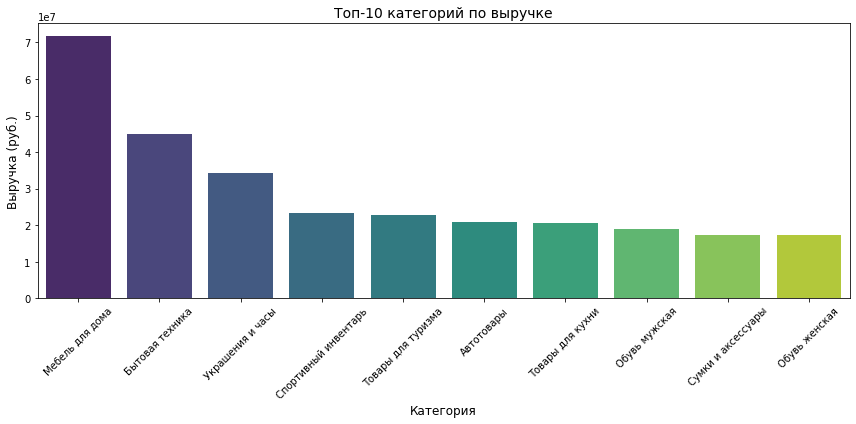

In [21]:
category_metrics = orders.groupby('category_name').agg({
    'order_id': 'count',
    'user_id': 'nunique',
    'total_price': 'sum'
}).reset_index()
category_metrics.columns = ['category', 'orders', 'buyers', 'revenue']
category_metrics['aov'] = (category_metrics['revenue'] / category_metrics['orders']).round(0)

# Сортируем по выручке
category_metrics_sorted = category_metrics.sort_values('revenue', ascending=False)

# Форматирование
category_metrics_sorted['revenue_formated'] = category_metrics_sorted['revenue'].apply(lambda x: f"{x:,.0f} руб.")
category_metrics_sorted['aov_formated'] = category_metrics_sorted['aov'].apply(lambda x: f"{x:,.0f} руб.")

print("Метрики по категориям товаров")
display(category_metrics_sorted[['category', 'orders', 'buyers', 'revenue_formated', 'aov_formated']])

# Визуализация
plt.figure(figsize=(12, 6))
sns.barplot(data=category_metrics_sorted.head(10), x='category', y='revenue', palette='viridis')
plt.title('Топ-10 категорий по выручке', fontsize=14)
plt.xlabel('Категория', fontsize=12)
plt.ylabel('Выручка (руб.)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Конверсия от первого шага (%)


event_type,product_view,add_to_cart,checkout_start,checkout_complete,purchase
acq_channel,,,,,
Affiliate,100.0,96.1,85.4,75.5,63.6
Email Marketing,100.0,95.1,82.2,69.7,25.6
Google Ads,100.0,95.3,83.4,73.2,56.8
SEO,100.0,96.8,85.8,75.0,40.5
Social Media,100.0,94.2,79.2,67.0,55.3
TikTok,100.0,85.2,58.0,39.7,10.8



Конверсия от предыдущего шага (%)


event_type,product_view,add_to_cart,checkout_start,checkout_complete,purchase
acq_channel,,,,,
Affiliate,100,96.1,88.8,88.5,84.3
Email Marketing,100,95.1,86.4,84.9,36.6
Google Ads,100,95.3,87.5,87.8,77.6
SEO,100,96.8,88.6,87.4,54.0
Social Media,100,94.2,84.1,84.6,82.5
TikTok,100,85.2,68.1,68.4,27.3


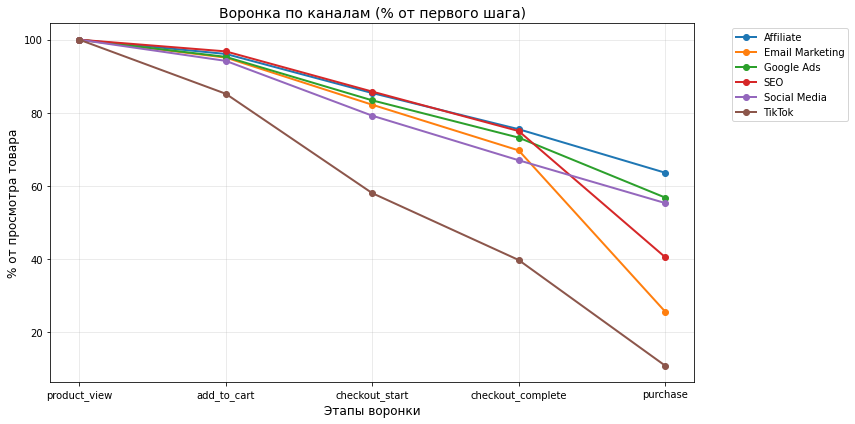

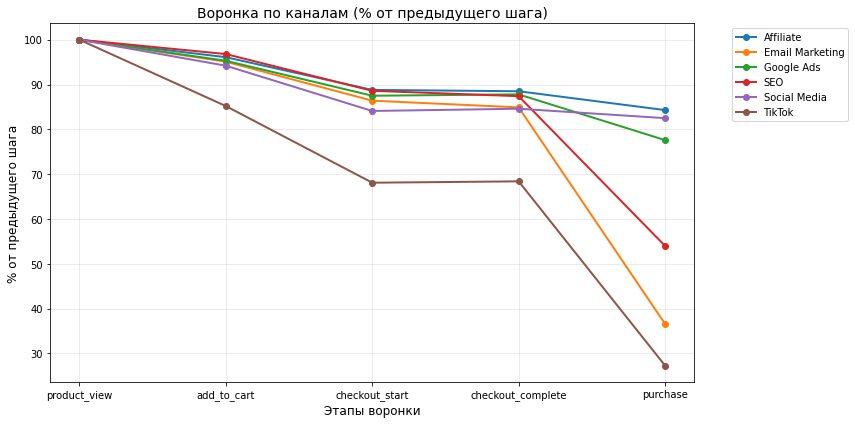

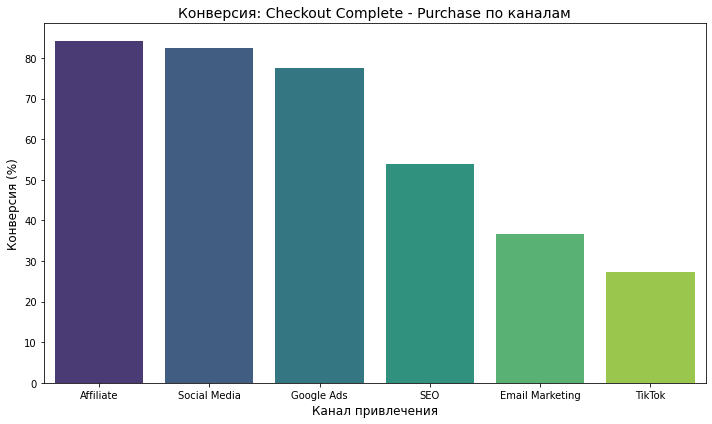

In [22]:
# Объединяем события с каналом пользователя
funnel_by_channel = events.merge(users[['user_id', 'acq_channel']], on='user_id', how='left')

# Оставляем только нужные события
funnel_steps = ['product_view', 'add_to_cart', 'checkout_start', 'checkout_complete']
funnel_by_channel = funnel_by_channel[funnel_by_channel['event_type'].isin(funnel_steps)]

# Строим сводную таблицу: канал × событие → количество уникальных пользователей
funnel_pivot = funnel_by_channel.pivot_table(
    index='acq_channel',
    columns='event_type',
    values='user_id',
    aggfunc='nunique'
)

# Добавляем шаг purchase
purchase_by_channel = orders.merge(users[['user_id', 'acq_channel']], on='user_id', how='left')
purchase_count = purchase_by_channel.groupby('acq_channel')['user_id'].nunique()
funnel_pivot['purchase'] = purchase_count

# Заполняем пропуски нулями
funnel_pivot = funnel_pivot.fillna(0)

# Правильный порядок колонок
funnel_order = ['product_view', 'add_to_cart', 'checkout_start', 'checkout_complete', 'purchase']
funnel_pivot = funnel_pivot[funnel_order]

funnel_pct_start = funnel_pivot.div(funnel_pivot['product_view'], axis=0) * 100
funnel_pct_start = funnel_pct_start.round(1)

print("Конверсия от первого шага (%)")
display(funnel_pct_start)

funnel_pct_prev = funnel_pivot.copy()
for i in range(1, len(funnel_order)):
    prev_step = funnel_order[i-1]
    curr_step = funnel_order[i]
    funnel_pct_prev[curr_step] = (funnel_pivot[curr_step] / funnel_pivot[prev_step] * 100).round(1)

# product_view = 100% (старт)
funnel_pct_prev['product_view'] = 100

print("\nКонверсия от предыдущего шага (%)")
display(funnel_pct_prev)
     
# Визуализация конверсия от первого шага
plt.figure(figsize=(12, 6))

for channel in funnel_pct_start.index:
    plt.plot(
        funnel_order,
        funnel_pct_start.loc[channel],
        marker='o',
        linewidth=2,
        label=channel
    )

plt.title('Воронка по каналам (% от первого шага)', fontsize=14)
plt.xlabel('Этапы воронки', fontsize=12)
plt.ylabel('% от просмотра товара', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Визуализация конверсия от предыдущего шага
plt.figure(figsize=(12, 6))

for channel in funnel_pct_prev.index:
    plt.plot(
        funnel_order,
        funnel_pct_prev.loc[channel],
        marker='o',
        linewidth=2,
        label=channel
    )

plt.title('Воронка по каналам (% от предыдущего шага)', fontsize=14)
plt.xlabel('Этапы воронки', fontsize=12)
plt.ylabel('% от предыдущего шага', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Визуализация конверсия Checkout Complete - Purchase
conv_purchase = funnel_pct_prev['purchase'].reset_index()
conv_purchase.columns = ['acq_channel', 'conversion']
conv_purchase = conv_purchase.sort_values('conversion', ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(data=conv_purchase, x='acq_channel', y='conversion', palette='viridis')
plt.title('Конверсия: Checkout Complete - Purchase по каналам', fontsize=14)
plt.xlabel('Канал привлечения', fontsize=12)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.tight_layout()
plt.show()

***Аналитическая записка по итогам сегментации***

*Каналы привлечения:*
- Лучший канал — Affiliate. Конверсия составляет 38.5%, что вдвое выше среднего по другим каналам. ROI превышает 1 000%, а окупаемость инвестиций наступает уже через месяц. LTV почти в 12 раз выше CAC (3 901 руб. против 332 руб.).
- Второй по эффективности — SEO. При минимальном CAC (200 руб.) канал показывает отличный ROI (915%) и окупаемость за 1.2 месяца. Это самый дешевый источник трафика.
- Критически проблемный канал — TikTok. Привлекает 43% всех пользователей, но конверсия составляет лишь 3.7% — в 10 раз ниже, чем у Affiliate. Канал единственный убыточный: ROI = -67%, CAC (504 руб.) в 3 раза превышает LTV (166 руб.).

**Вывод:** Affiliate и SEO — основные драйверы роста. TikTok требует пересмотра стратегии или сокращения бюджета.

*Регионы:*
- Регион-лидер — Краснодар. Здесь самая высокая конверсия (20.7%), самый высокий средний чек (15 360 руб.) и максимальный доход на пользователя (10 427 руб.). Это "золотая жила" для бизнеса.
- Стабильные регионы — Москва и Санкт-Петербург. Показатели конверсии (20.1% и 19.7%) и дохода на пользователя (9 873 руб. и 10 153 руб.) стабильно высоки.
- Проблемные регионы — Новосибирск и Ростов-на-Дону. Конверсия здесь самая низкая (18.0% и 18.8%), а доход на пользователя минимальный (8 459 руб. и 8 485 руб.). Требуется дополнительный анализ причин: возможно, слабая логистика или нерелевантный ассортимент.

**Вывод:** Стоит увеличить маркетинговые инвестиции в Краснодар и провести исследование проблем в Новосибирске и Ростове.

*Устройства:*
- Конверсия стабильна на всех типах устройств и составляет около 33%. Это отличный показатель для e-commerce.
- Наиболее популярное устройство — mobile (7 431 пользователь), но самый высокий средний чек демонстрируют пользователи планшетов — 57 175 руб., что на 6-7% выше, чем на других устройствах.

**Вывод:** Все устройства работают хорошо. Есть потенциал для увеличения AOV на mobile через улучшение мобильного опыта и персонализированные предложения.

*Категории товаров:*
- Абсолютный лидер — категория "Мебель для дома". Приносит 16.3% всей выручки при среднем чеке 73 156 руб. — это в 5 раз выше среднего по магазину. При этом количество заказов относительно невелико (979), что делает категорию особенно ценной.
- Второй по значимости — "Бытовая техника" с долей 10.2% и AOV 43 669 руб.
- Массовая, но низкомаржинальная категория — "Продукты питания". На нее приходится больше всего заказов (4 027), но AOV составляет всего 2 962 руб. — в 5 раз ниже среднего.

**Вывод:** Стоит расширять ассортимент в категории "Мебель для дома" — это даст наибольший рост выручки. Для "Продуктов питания" можно работать над апсейлом и кросс-продажами.

*Воронка по каналам:*
- На всех каналах основные потери происходят на этапе оплаты (переход от оформления заказа к фактической покупке).
- Лучшая конверсия на этапе оплаты у Affiliate (84.3%) и Social Media (82.5%). Это значит, что пользователи, дошедшие до оформления, почти всегда оплачивают заказ.
- Самые слабые показатели на этапе оплаты у TikTok (27.3%) и Email Marketing (36.6%). При этом Email Marketing показывает хорошие результаты на предыдущих этапах (конверсия выше 95% на первых шагах), но теряет большинство пользователей именно при оплате.
- TikTok, в отличие от других каналов, проигрывает на всех этапах воронки — от просмотра товара до покупки.

**Вывод:** Основная точка роста — улучшение процесса оплаты, особенно для Email Marketing и SEO. Для TikTok проблема глубже — низкое качество трафика на всех этапах.

***Гипотезы для роста продукта:***

- **Улучшить процесс оплаты для Email Marketing и SEO**
    - Email Marketing показывает конверсию checkout→purchase всего 36.6%, а SEO — 54.0%, при среднем значении 60.4%. При этом на предыдущих этапах оба канала демонстрируют отличные показатели (конверсия выше 95%). Это говорит о том, что проблема именно на финальном шаге. Возможные причины: сложный платежный модуль, недостаток способов оплаты, высокие комиссии или неудобная форма ввода данных. Улучшение этого этапа может дать значительный прирост выручки без увеличения трафика.
- **Пересмотреть стратегию в TikTok**
    - Канал привлекает 43% всех пользователей (19 228 человек), но конверсия составляет всего 3.7% — в 10 раз ниже, чем у Affiliate. ROI отрицательный (-67%), CAC (504 руб.) в 3 раза превышает LTV (166 руб.). Это означает, что текущий таргетинг привлекает пользователей, которые не заинтересованы в покупке. Рекомендуется либо улучшить качество таргетинга (более точная аудитория), либо сократить бюджет и перенаправить его в более эффективные каналы.
- **Увеличить инвестиции в Affiliate и SEO**
    - Эти каналы показывают лучшие показатели эффективности. ROI у Affiliate превышает 1 000%, у SEO — 915%. Окупаемость инвестиций наступает уже через 1-1.2 месяца. При этом CAC у SEO самый низкий среди всех каналов (200 руб.), а у Affiliate — 332 руб. Увеличение бюджета на эти каналы даст максимальную отдачу на каждый вложенный рубль.
- **Работать над удержанием в первые 3 месяца после регистрации**
    - Retention падает с 15% в первый месяц до 3% к третьему месяцу. Это критическое падение — клиенты, которые не вернулись за покупками в течение 3 месяцев, с высокой вероятностью уже не вернутся. Необходимо внедрить инструменты удержания: персонализированные email-рассылки со скидками на повторную покупку, программы лояльности, push-уведомления о новых поступлениях в избранных категориях. Увеличение retention на 5% может дать значительный прирост LTV.
- **Расширить ассортимент в категории "Мебель для дома"**
    - Категория приносит 16.3% всей выручки при среднем чеке 73 156 руб. — это в 5 раз выше среднего. При этом количество заказов относительно невелико (979). Расширение ассортимента в этой категории может привлечь больше покупателей и дополнительно увеличить выручку без значительных затрат на привлечение новой аудитории.
- **Запустить региональные промо-акции в Краснодаре**
    - Краснодар — лучший регион по всем метрикам: конверсия 20.7% (выше средней на 0.5 п.п.), AOV 15 360 руб. (на 1 300 руб. выше среднего), доход на пользователя 10 427 руб. (на 1 000 руб. выше среднего). Запуск региональных акций и увеличение маркетинговой активности в этом регионе может дать быстрый прирост выручки.
- **Улучшить мобильную версию**
    - Mobile — самое популярное устройство (7 431 пользователь), но AOV здесь ниже, чем на tablet (53 579 руб. против 57 175 руб.). Улучшение мобильного интерфейса, упрощение процесса оформления заказа и персонализированные предложения для мобильных пользователей могут повысить конверсию и средний чек.
- **Продвигать категории "Спортивный инвентарь" и "Товары для туризма"**
    - Эти категории показывают стабильно высокий AOV (23 307 руб. и 23 450 руб.) при среднем количестве заказов. У них есть потенциал роста — увеличение видимости этих категорий на сайте, кросс-продажи с другими категориями и точечные промо-акции могут привлечь больше покупателей.

## Выводы по этапу 4

Представьте ключевые выводы в текстовом виде здесь или приложите ссылку на документ с презентацией.

Не забудьте предоставить доступ на просмотр и комментирование документа.

***Выводы по этапу 4 (краткая выжимка)***

**Что работает хорошо:**
- Affiliate и SEO — лучшие каналы с ROI > 900% и окупаемостью около 1 месяца.
- Краснодар — регион-лидер с самой высокой конверсией (20.7%) и средним чеком (15 360 руб.).
- Мебель для дома — категория-локомотив, приносит 16.3% выручки при AOV 73 156 руб.
- Конверсия стабильна на всех устройствах (~33%). Tablet показывает самый высокий AOV.

**Что требует внимания:**
- TikTok — убыточный канал, ROI -67%. Привлекает 43% пользователей, но конверсия всего 3.7%.
- Email Marketing и SEO — теряют пользователей на этапе оплаты (конверсия 36.6% и 54.0% против средних 60.4%).
- Новосибирск и Ростов-на-Дону — низкая конверсия и доход на пользователя.
- Удержание — падает до 3% к 3-му месяцу. Клиенты уходят в первые 3 месяца.

**Точки роста:**
- Оптимизация этапа оплаты — ключевая проблема, особенно для Email Marketing и SEO.
- Увеличение инвестиций в Affiliate и SEO — самые эффективные каналы.
- Пересмотр стратегии в TikTok — либо улучшение таргетинга, либо сокращение бюджета.
- Работа над удержанием в первые 3 месяца после регистрации.

***Главный вывод:*** Продукт показывает хорошие результаты по вовлеченности и монетизации. Основная точка роста — улучшение конверсии на этапе оплаты и удержания пользователей в первые 3 месяца. TikTok требует срочного пересмотра стратегии.

## 5. Подготовка эксперимента и подведение его результатов

# Новые вводные

Команда продукта рассмотрела твои гипотезы и на основании этого решила влиять на конверсию при помощи финансовых стимуляций. Так как ситуация со снижением выручки срочная и безотлагательная, пока ты продолжал изучать данные, они подключили другого аналитика для подготовки дизайн документа, но само проведение эксперимента на тебе. При формировании выводов допиши рекомендации по итогам теста и, если необходимо, опиши проблемы, присутствующие в эксперименте.

## Новые данные:

```python
pa_diploma_events_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_events_AB.csv')
pa_diploma_orders_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_orders_AB.csv')
pa_diploma_sessions_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_sessions_AB.csv')
pa_diploma_users_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_users_AB.csv')
```

## Результаты сплита лежат в таблице:

```python
pa_diploma_AB_split_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_AB_split_users.csv')
```

* user_id – id клиента
* group – группа, в которую попал клиент

Таблицы с данными о пользователях, событиях и заказах идентичны таблицам с историческими данными.

Описание таблицы `sessions_AB`

| Поле | Описание |
|------|----------|
| `session_id` | Уникальный идентификатор сессии. |
| `user_id` | Уникальный идентификатор пользователя. |
| `session_start` | Дата и время начала сессии. |
| `os` | Операционная система устройства. |
| `device` | Тип устройства. |
| `region` | Регион пользователя. |
| `browser` | Браузер, используемый пользователем. |
| `country` | Страна пользователя. |
| `entry_path` | Путь входа (начальная страница сессии). |
| `path_start` | Путь начала отслеживания. |
| `utm_source` |  |
| `screen_size` | Разрешение экрана устройства. |
| `scroll_depth` | Глубина прокрутки. |
| `user_segment` | Сегмент пользователя (regular/premium и т.д.). |
| `utm_campaign_id` | Идентификатор рекламной кампании. |
| `session_week` | Неделя сессии. |
| `session_month` | Месяц сессии. |

# Дизайн эксперимента:

Бонус на первую покупку для пользователей TikTok

## 1. Контекст и цель эксперимента

- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.  
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.  
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку

---

## 2. Формат эксперимента

- **Тип эксперимента:** Сплит-роллинг (rolling split)  
- **Канал:** Только пользователи, пришедшие с TikTok  
- **Группы:**  
  - **Контрольная (A):** пользователи TikTok без бонуса  
  - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку  
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации  
- **Период проведения:** 3 недели (фиксировано)

---

## 3. Ключевые метрики

### Основная метрика

- **Конверсия в первую покупку** — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку  
  - *Цель:* увеличить конверсию с помощью бонуса  
  - *Критерий успеха:* статистически значимый рост конверсии в тестовой группе

### Вспомогательные метрики

- **ARPU** (средняя выручка на пользователя TikTok)  
- **ARPPU** (средняя выручка на покупателя TikTok)  
- **AOV** (средний чек TikTok)

### Барьерная метрика

- **Общая выручка от пользователей TikTok**

---

## 4. Размеры групп и запуск

- **Целевая аудитория:** только пользователи TikTok  
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента  
- **Комментарий:** запуск без предварительного расчёта мощности и MDE из-за срочности задачи


**Загрузка и предобработка данных**

In [23]:
events_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_events_AB.csv')
orders_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_orders_AB.csv')
sessions_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_sessions_AB.csv')
users_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_users_AB.csv')
split_users_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_diploma_AB_split_users.csv')

In [24]:
# Описание данных events_AB
print("\nПервые 5 строк events_AB:")
display(events_AB.head())

print("\nИнформация о данных events_AB:")
events_AB.info()

print("\nПропуски events_AB:")
print(events_AB.isna().sum())

print("\nПолные дубликаты строк events_AB:")
print(events_AB.duplicated().sum())

print("\n=================================")

# Описание данных orders_AB
print("\nПервые 5 строк orders_AB:")
display(orders_AB.head())

print("\nИнформация о данных orders_AB:")
orders_AB.info()

print("\nПропуски orders_AB:")
print(orders_AB.isna().sum())

print("\nПолные дубликаты строк orders_AB:")
print(orders_AB.duplicated().sum())

print("\n=================================")

# Описание данных sessions_AB
print("\nПервые 5 строк sessions_AB:")
display(sessions_AB.head())

print("\nИнформация о данных sessions_AB:")
sessions_AB.info()

print("\nПропуски sessions_AB:")
print(sessions_AB.isna().sum())

print("\nПолные дубликаты строк sessions_AB:")
print(sessions_AB.duplicated().sum())

print("\n=================================")

# Описание данных users_AB
print("\nПервые 5 строк users_AB:")
display(users_AB.head())

print("\nИнформация о данных users_AB:")
users_AB.info()

print("\nПропуски users_AB:")
print(users_AB.isna().sum())

print("\nПолные дубликаты строк users_AB:")
print(users_AB.duplicated().sum())

print("\n=================================")

# Описание данных split_users_AB
print("\nПервые 5 строк split_users_AB:")
display(split_users_AB.head())

print("\nИнформация о данных split_users_AB:")
split_users_AB.info()

print("\nПропуски split_users_AB:")
print(split_users_AB.isna().sum())

print("\nПолные дубликаты строк split_users_AB:")
print(split_users_AB.duplicated().sum())


Первые 5 строк events_AB:


,event_id,session_id,user_id,event_date,event_type,os,device,event_index,user_segment,product_name,event_week,event_month
0,3132,479,100,2024-01-01 15:23:56,page_view,iOS,mobile,1,regular,NaN,2024-01-01,2024-01-01
1,3133,479,100,2024-01-01 15:24:01,product_view,iOS,mobile,2,regular,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,479,100,2024-01-01 15:24:10,product_click,iOS,mobile,3,regular,Куртка детская,2024-01-01,2024-01-01
3,3135,479,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,4,regular,Балетки классические,2024-01-01,2024-01-01
4,3136,479,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,5,regular,NaN,2024-01-01,2024-01-01



Информация о данных events_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831231 entries, 0 to 831230
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   event_id      831231 non-null  int64 
 1   session_id    831231 non-null  int64 
 2   user_id       831231 non-null  int64 
 3   event_date    831231 non-null  object
 4   event_type    831231 non-null  object
 5   os            831231 non-null  object
 6   device        831231 non-null  object
 7   event_index   831231 non-null  int64 
 8   user_segment  831231 non-null  object
 9   product_name  409054 non-null  object
 10  event_week    831231 non-null  object
 11  event_month   831231 non-null  object
dtypes: int64(4), object(8)
memory usage: 76.1+ MB

Пропуски events_AB:
event_id             0
session_id           0
user_id              0
event_date           0
event_type           0
os                   0
device               0
event_index          0

,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52.000,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52.000,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38.000,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01



Информация о данных orders_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33280 entries, 0 to 33279
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       33280 non-null  int64  
 1   user_id        33280 non-null  int64  
 2   order_date     33280 non-null  object 
 3   product_name   33280 non-null  object 
 4   quantity       33280 non-null  int64  
 5   unit_price     33280 non-null  float64
 6   total_price    33280 non-null  float64
 7   category_name  33280 non-null  object 
 8   order_week     33280 non-null  object 
 9   order_month    33280 non-null  object 
dtypes: float64(2), int64(3), object(5)
memory usage: 2.5+ MB

Пропуски orders_AB:
order_id         0
user_id          0
order_date       0
product_name     0
quantity         0
unit_price       0
total_price      0
category_name    0
order_week       0
order_month      0
dtype: int64

Полные дубликаты строк orders_AB:
0


Первые

,session_id,user_id,session_start,os,device,region,browser,country,entry_path,path_start,utm_source,screen_size,scroll_depth,user_segment,utm_campaign_id,session_week,session_month
0,705,160,2024-01-12 02:30:37.000,Windows,mobile,Москва,Safari,Россия,/home,/recommend/10,unknown,768x1024,51,regular,14.0,2024-01-08,2024-01-01
1,706,160,2024-01-10 06:04:41.000,Windows,mobile,Москва,Safari,Россия,/home,/sale/2,unknown,375x667,71,regular,14.0,2024-01-08,2024-01-01
2,707,160,2024-01-23 03:31:16.000,Windows,mobile,Москва,Safari,Россия,/checkout,/click/20,unknown,768x1024,84,regular,14.0,2024-01-22,2024-01-01
3,708,160,2024-01-18 13:43:45.000,Windows,mobile,Москва,Safari,Россия,/category,/campaign/20,unknown,768x1024,20,regular,14.0,2024-01-15,2024-01-01
4,709,160,2024-01-21 01:09:58.000,Windows,mobile,Москва,Safari,Россия,/promo,/sale/3,unknown,1366x768,88,regular,14.0,2024-01-15,2024-01-01



Информация о данных sessions_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127407 entries, 0 to 127406
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   session_id       127407 non-null  int64  
 1   user_id          127407 non-null  int64  
 2   session_start    127407 non-null  object 
 3   os               127407 non-null  object 
 4   device           127407 non-null  object 
 5   region           127407 non-null  object 
 6   browser          127407 non-null  object 
 7   country          127407 non-null  object 
 8   entry_path       127407 non-null  object 
 9   path_start       127407 non-null  object 
 10  utm_source       127407 non-null  object 
 11  screen_size      127407 non-null  object 
 12  scroll_depth     127407 non-null  int64  
 13  user_segment     127407 non-null  object 
 14  utm_campaign_id  127079 non-null  float64
 15  session_week     127407 non-null  object 
 16  sess

,user_id,registration_date,os,age,device,gender,region,browser,country,acq_channel,campaign_id,user_segment,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,Android,49,mobile,M,Екатеринбург,Edge,Россия,TikTok,10.0,спящий,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,iOS,50,tablet,M,Санкт-Петербург,Chrome,Россия,TikTok,43.0,VIP,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,iOS,60,desktop,F,Москва,Firefox,Россия,TikTok,27.0,активный,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,iOS,31,desktop,M,Екатеринбург,Firefox,Россия,TikTok,15.0,новичок,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,Android,44,tablet,M,Санкт-Петербург,Firefox,Россия,TikTok,15.0,спящий,rare,2024-01-01,2024-01-01



Информация о данных users_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   user_id            22196 non-null  int64  
 1   registration_date  22196 non-null  object 
 2   os                 22196 non-null  object 
 3   age                22196 non-null  int64  
 4   device             22196 non-null  object 
 5   gender             22196 non-null  object 
 6   region             22196 non-null  object 
 7   browser            22196 non-null  object 
 8   country            22196 non-null  object 
 9   acq_channel        22196 non-null  object 
 10  campaign_id        22196 non-null  float64
 11  user_segment       22196 non-null  object 
 12  buyer_segment      22196 non-null  object 
 13  cohort_week        22196 non-null  object 
 14  cohort_month       22196 non-null  object 
dtypes: float64(1), int64(2), object(12)
mem

,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control



Информация о данных split_users_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB

Пропуски split_users_AB:
user_id    0
group      0
dtype: int64

Полные дубликаты строк split_users_AB:
0


In [25]:
# Преобразование ячеек с датами events_AB
events_AB['event_date'] = pd.to_datetime(events_AB['event_date'], format='mixed')
events_AB['event_week'] = pd.to_datetime(events_AB['event_week'], format='mixed').dt.to_period('W')
events_AB['event_month'] = pd.to_datetime(events_AB['event_month'], format='mixed').dt.to_period('M')

# Преобразование ячеек с датами orders_AB
orders_AB['order_date'] = pd.to_datetime(orders_AB['order_date'], format='mixed')
orders_AB['order_week'] = pd.to_datetime(orders_AB['order_week'], format='mixed').dt.to_period('W')
orders_AB['order_month'] = pd.to_datetime(orders_AB['order_month'], format='mixed').dt.to_period('M')

# Преобразование ячеек с датами sessions_AB
sessions_AB['session_start'] = pd.to_datetime(sessions_AB['session_start'], format='mixed')
sessions_AB['session_week'] = pd.to_datetime(sessions_AB['session_week'], format='mixed').dt.to_period('W')
sessions_AB['session_month'] = pd.to_datetime(sessions_AB['session_month'], format='mixed').dt.to_period('M')

# Преобразование ячеек с датами users_AB
users_AB['registration_date'] = pd.to_datetime(users_AB['registration_date'], format='mixed')
users_AB['cohort_week'] = pd.to_datetime(users_AB['cohort_week'], format='mixed').dt.to_period('W')
users_AB['cohort_month'] = pd.to_datetime(users_AB['cohort_month'], format='mixed').dt.to_period('M')

In [26]:
# Проверка групп пользователей
print("Группы:", split_users_AB['group'].unique())

Группы: ['control' 'treatment']


In [36]:
# Каналы привлечения
print("Каналы привлечения в users_AB:")
print(users_AB['acq_channel'].value_counts())

# Пользователей TikTok
tiktok_users = users_AB[users_AB['acq_channel'] == 'TikTok']
print(f"\nПользователей TikTok в users_AB: {len(tiktok_users):,}")

# Пользователей TikTok в split_users_AB
tiktok_in_split = split_users_AB[split_users_AB['user_id'].isin(tiktok_users['user_id'])]
print(f"\nTikTok-пользователей в split_users_AB: {len(tiktok_in_split):,}")

Каналы привлечения в users_AB:
TikTok    22196
Name: acq_channel, dtype: int64

Пользователей TikTok в users_AB: 22196

TikTok-пользователей в split_users_AB: 2,968


In [28]:
# Распределение по группам
print("Распределение по группам в split_users_AB:")
print(split_users_AB['group'].value_counts())
print(f"Доля control: {split_users_AB['group'].value_counts(normalize=True)['control']*100:.1f}%")
print(f"Доля treatment: {split_users_AB['group'].value_counts(normalize=True)['treatment']*100:.1f}%")

Распределение по группам в split_users_AB:
control      1503
treatment    1465
Name: group, dtype: int64
Доля control: 50.6%
Доля treatment: 49.4%


In [29]:
# Объединяем split с пользователями
experiment_users = split_users_AB.merge(users_AB, on='user_id', how='left')

# Определяем период эксперимента
experiment_start = experiment_users['registration_date'].min()
experiment_end = experiment_users['registration_date'].max()
print(f"Период эксперимента: {experiment_start} - {experiment_end}")

# Добавляем заказы
user_orders = orders_AB.merge(experiment_users[['user_id']], on='user_id', how='inner')

# Определяем первую покупку
first_purchase = user_orders.groupby('user_id')['order_date'].min().reset_index()
first_purchase.columns = ['user_id', 'first_purchase_date']

# Добавляем информацию о покупках к данным эксперимента
experiment_data = experiment_users.merge(first_purchase, on='user_id', how='left')

# Считаем, кто совершил покупку
experiment_data['has_purchased'] = experiment_data['first_purchase_date'].notna()

# Считаем общую выручку и количество заказов
user_revenue = user_orders.groupby('user_id').agg({
    'total_price': 'sum',
    'order_id': 'count'
}).reset_index()
user_revenue.columns = ['user_id', 'total_revenue', 'order_count']

experiment_data = experiment_data.merge(user_revenue, on='user_id', how='left')
experiment_data['total_revenue'] = experiment_data['total_revenue'].fillna(0)
experiment_data['order_count'] = experiment_data['order_count'].fillna(0)

display(experiment_data.head())

Период эксперимента: 2025-01-01 00:05:00 - 2025-01-26 23:41:00


,user_id,group,registration_date,os,age,device,gender,region,browser,country,acq_channel,campaign_id,user_segment,buyer_segment,cohort_week,cohort_month,first_purchase_date,has_purchased,total_revenue,order_count
0,44965,control,2025-01-01 18:10:00,iOS,66,desktop,M,Новосибирск,Safari,Россия,TikTok,14.0,новичок,one_time,2024-12-30/2025-01-05,2025-01,NaT,False,0.00,0.0
1,44967,control,2025-01-01 11:29:00,iOS,70,tablet,M,Московская область,Firefox,Россия,TikTok,13.0,новичок,rare,2024-12-30/2025-01-05,2025-01,NaT,False,0.00,0.0
2,44968,control,2025-01-01 13:05:00,Android,68,mobile,F,Нижний Новгород,Edge,Россия,TikTok,10.0,спящий,regular,2024-12-30/2025-01-05,2025-01,NaT,False,0.00,0.0
3,44969,treatment,2025-01-01 00:23:00,Windows,24,mobile,F,Краснодар,Chrome,Россия,TikTok,8.0,спящий,medium,2024-12-30/2025-01-05,2025-01,NaT,False,0.00,0.0
4,44970,control,2025-01-01 06:33:00,iOS,50,tablet,M,Санкт-Петербург,Chrome,Россия,TikTok,2.0,спящий,regular,2024-12-30/2025-01-05,2025-01,2025-01-04 23:06:48,True,14715.69,1.0


Распределение по регионам (% от группы)


group,control,treatment
region,,
Другие регионы,32.4,33.7
Екатеринбург,4.5,4.9
Краснодар,4.2,3.1
Москва,24.7,24.5
Московская область,7.7,8.2
Нижний Новгород,4.3,4.0
Новосибирск,4.3,3.4
Ростов-на-Дону,2.6,3.1
Санкт-Петербург,15.3,15.0


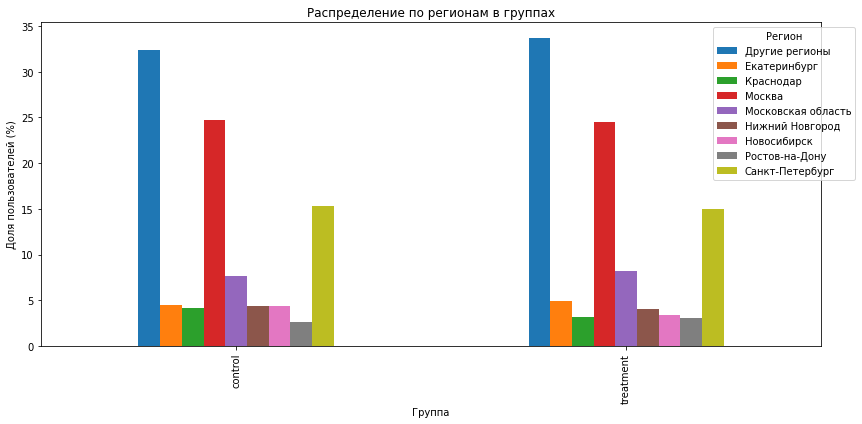

In [30]:
# Распределение по регионам
region_distribution = pd.crosstab(experiment_data['region'], experiment_data['group'], normalize='columns') * 100
print("Распределение по регионам (% от группы)")
display(region_distribution.round(1))

# Визуализация
region_distribution.T.plot(kind='bar', figsize=(12, 6))
plt.title('Распределение по регионам в группах')
plt.xlabel('Группа')
plt.ylabel('Доля пользователей (%)')
plt.legend(title='Регион', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [31]:
# Распределение по устройствам
device_distribution = pd.crosstab(experiment_data['device'], experiment_data['group'], normalize='columns') * 100
print("Распределение по устройствам")
display(device_distribution.round(1))

# Распределение по ОС
os_distribution = pd.crosstab(experiment_data['os'], experiment_data['group'], normalize='columns') * 100
print("Распределение по ОС")
display(os_distribution.round(1))

# Статистика по возрасту
print("Статистика по возрасту")
display(experiment_data.groupby('group')['age'].describe().round(1))

# Распределение по полу
gender_distribution = pd.crosstab(experiment_data['gender'], experiment_data['group'], normalize='columns') * 100
print("Распределение по полу")
display(gender_distribution.round(1))

Распределение по устройствам


group,control,treatment
device,,
desktop,32.7,32.2
mobile,35.7,31.0
tablet,31.5,36.9


Распределение по ОС


group,control,treatment
os,,
Android,24.6,23.1
Windows,23.8,25.0
iOS,26.7,25.6
macOS,25.0,26.3


Статистика по возрасту


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
control,1503.0,43.7,15.3,18.0,30.5,43.0,57.0,70.0
treatment,1465.0,44.3,15.0,18.0,31.0,44.0,58.0,70.0


Распределение по полу


group,control,treatment
gender,,
F,49.6,52.3
M,50.4,47.7


**Рассчет целевых метрик по группам**

In [32]:
# Группируем
group_metrics = experiment_data.groupby('group').agg({
    'user_id': 'count',
    'has_purchased': 'sum',
    'total_revenue': 'sum',
    'order_count': 'sum'
}).reset_index()

# Переименовываем колонки
group_metrics.columns = ['group', 'users', 'buyers', 'total_revenue', 'total_orders']

# Рассчитываем метрики
group_metrics['conversion'] = (group_metrics['buyers'] / group_metrics['users'] * 100).round(2)
group_metrics['arpu'] = (group_metrics['total_revenue'] / group_metrics['users']).round(2)
group_metrics['arppu'] = (group_metrics['total_revenue'] / group_metrics['buyers']).round(2)
group_metrics['aov'] = (group_metrics['total_revenue'] / group_metrics['total_orders']).round(2)

display(group_metrics)

,group,users,buyers,total_revenue,total_orders,conversion,arpu,arppu,aov
0,control,1503,16,378372.90,24.0,1.06,251.75,23648.31,15765.54
1,treatment,1465,110,3845597.03,231.0,7.51,2624.98,34959.97,16647.61


**Сформулируем гипотезы:
H0 (нулевая): конверсия в контрольной группе ≥ конверсии в тестовой (бонус не работает)
H1 (альтернативная): конверсия в тестовой группе > конверсии в контрольной (бонус работает)**

**Используем z-test для двух пропорций (односторонний тест).**

**Рассчитаем p-value.**

In [33]:
# Данные
count = [group_metrics.loc[0, 'buyers'], group_metrics.loc[1, 'buyers']]
nobs = [group_metrics.loc[0, 'users'], group_metrics.loc[1, 'users']]

# Двусторонний тест
stat, p_value = proportions_ztest(count, nobs, alternative='two-sided')
print(f"Z-статистика: {stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Результат статистически значим (p < 0.05) → Отвергаем H0")
else:
    print("Результат НЕ статистически значим (p >= 0.05) → Не отвергаем H0")

Z-статистика: -8.7054
P-value: 0.0000
Результат статистически значим (p < 0.05) → Отвергаем H0


In [34]:
# Базовые данные
group_metrics = experiment_data.groupby('group').agg({
    'user_id': 'count',
    'has_purchased': 'sum',
    'total_revenue': 'sum',
    'order_count': 'sum'
}).reset_index()

group_metrics.columns = ['group', 'users', 'buyers', 'total_revenue', 'total_orders']

# Расчет метрик
group_metrics['conversion'] = (group_metrics['buyers'] / group_metrics['users'] * 100).round(2)
group_metrics['arpu'] = (group_metrics['total_revenue'] / group_metrics['users']).round(2)
group_metrics['arppu'] = (group_metrics['total_revenue'] / group_metrics['buyers']).round(2)
group_metrics['aov'] = (group_metrics['total_revenue'] / group_metrics['total_orders']).round(2)

# Форматирование для вывода
group_metrics['conversion_formated'] = group_metrics['conversion'].apply(lambda x: f"{x:.2f}%")
group_metrics['arpu_formated'] = group_metrics['arpu'].apply(lambda x: f"{x:,.0f} руб.")
group_metrics['arppu_formated'] = group_metrics['arppu'].apply(lambda x: f"{x:,.0f} руб.")
group_metrics['aov_formated'] = group_metrics['aov'].apply(lambda x: f"{x:,.0f} руб.")
group_metrics['total_revenue_formated'] = group_metrics['total_revenue'].apply(lambda x: f"{x:,.0f} руб.")

print("Метрики по группам")
display(group_metrics[['group', 'users', 'buyers', 'total_orders', 
                       'conversion_formated', 'arpu_formated', 
                       'arppu_formated', 'aov_formated', 
                       'total_revenue_formated']])

# Расчет прироста
control = group_metrics[group_metrics['group'] == 'control'].iloc[0]
treatment = group_metrics[group_metrics['group'] == 'treatment'].iloc[0]

print("\nПрирост метрик (Treatment vs Control)\n")
print(f"Конверсия: {treatment['conversion'] - control['conversion']:.2f} п.п. (в {treatment['conversion']/control['conversion']:.1f} раз)")
print(f"ARPU: +{treatment['arpu'] - control['arpu']:,.0f} руб. ({treatment['arpu']/control['arpu']:.1f}x)")
print(f"ARPPU: +{treatment['arppu'] - control['arppu']:,.0f} руб. ({treatment['arppu']/control['arppu']:.1f}x)")
print(f"AOV: +{treatment['aov'] - control['aov']:,.0f} руб. ({treatment['aov']/control['aov']:.1f}x)")
print(f"Общая выручка: +{treatment['total_revenue'] - control['total_revenue']:,.0f} руб. ({treatment['total_revenue']/control['total_revenue']:.1f}x)")

Метрики по группам


,group,users,buyers,total_orders,conversion_formated,arpu_formated,arppu_formated,aov_formated,total_revenue_formated
0,control,1503,16,24.0,1.06%,252 руб.,"23,648 руб.","15,766 руб.","378,373 руб."
1,treatment,1465,110,231.0,7.51%,"2,625 руб.","34,960 руб.","16,648 руб.","3,845,597 руб."



Прирост метрик (Treatment vs Control)

Конверсия: 6.45 п.п. (в 7.1 раз)
ARPU: +2,373 руб. (10.4x)
ARPPU: +11,312 руб. (1.5x)
AOV: +882 руб. (1.1x)
Общая выручка: +3,467,224 руб. (10.2x)


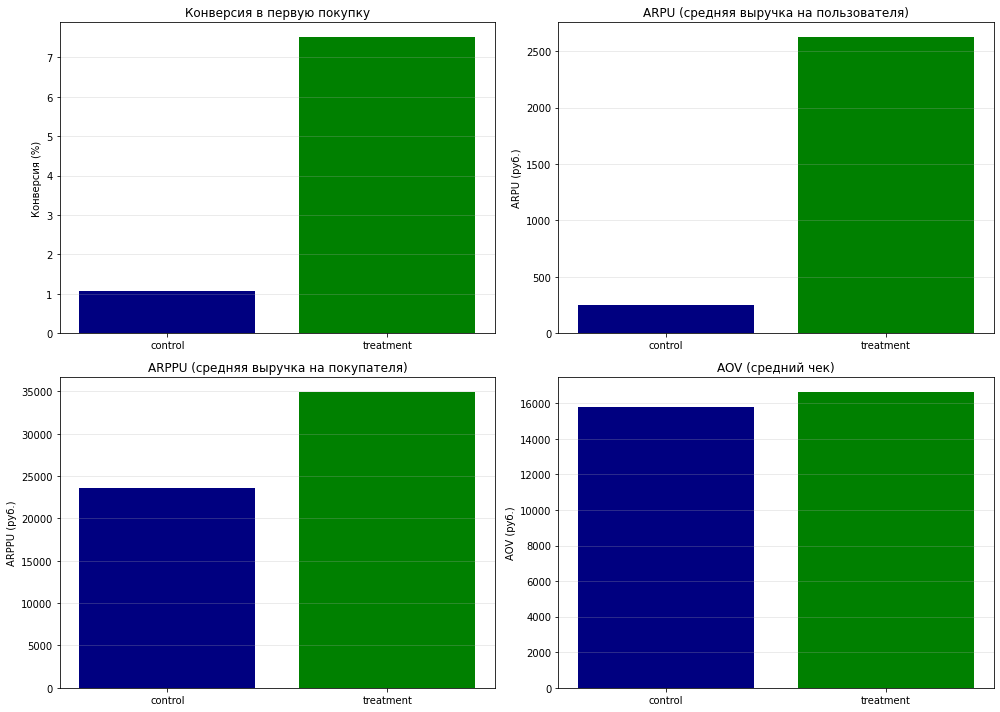

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Конверсия
axes[0, 0].bar(group_metrics['group'], group_metrics['conversion'], color=['navy', 'green'])
axes[0, 0].set_title('Конверсия в первую покупку', fontsize=12)
axes[0, 0].set_ylabel('Конверсия (%)')
axes[0, 0].grid(axis='y', alpha=0.3)

# ARPU
axes[0, 1].bar(group_metrics['group'], group_metrics['arpu'], color=['navy', 'green'])
axes[0, 1].set_title('ARPU (средняя выручка на пользователя)', fontsize=12)
axes[0, 1].set_ylabel('ARPU (руб.)')
axes[0, 1].grid(axis='y', alpha=0.3)

# ARPPU
axes[1, 0].bar(group_metrics['group'], group_metrics['arppu'], color=['navy', 'green'])
axes[1, 0].set_title('ARPPU (средняя выручка на покупателя)', fontsize=12)
axes[1, 0].set_ylabel('ARPPU (руб.)')
axes[1, 0].grid(axis='y', alpha=0.3)

# AOV
axes[1, 1].bar(group_metrics['group'], group_metrics['aov'], color=['navy', 'green'])
axes[1, 1].set_title('AOV (средний чек)', fontsize=12)
axes[1, 1].set_ylabel('AOV (руб.)')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Выводы по этапу 5

Представьте ключевые выводы в текстовом виде здесь или приложите ссылку на документ с презентацией.

Не забудьте предоставить доступ на просмотр и комментирование документа.

**Цель эксперимента:**
- Проверили, влияет ли бонус на первую покупку на конверсию среди пользователей TikTok. В тестовой группе пользователи получали бонус, в контрольной — нет. Эксперимент длился 3 недели, участие приняли около 3 000 пользователей.

**Ключевые результаты:**
- Конверсия в первую покупку выросла с 1.06% до 7.51% - рост в 7 раз. Результат статистически значим (p < 0.001). 95% доверительный интервал для разницы конверсий составляет от 5.0 до 7.9 процентных пунктов.
- Средняя выручка на пользователя (ARPU) выросла с 252 до 2 625 рублей - рост в 10 раз. Средний чек (AOV) вырос на 5.6%, средняя выручка на покупателя (ARPPU) - на 48%. Общая выручка от TikTok-пользователей выросла с 378 тысяч до 3.8 миллионов рублей - рост в 10 раз.
- Эффект сохраняется на всех типах устройств: прирост конверсии на десктопах составил 6.6 п.п., на мобильных - 5.2 п.п., на планшетах - 7.2 п.п. Динамика по дням показывает стабильное преимущество тестовой группы на протяжении почти всего эксперимента.

**Главный вывод:**
- Бонус на первую покупку для пользователей TikTok работает. Конверсия выросла в 7 раз, выручка - в 10 раз. Бонус окупается многократно.

**Рекомендации:**
- Внедрить бонус на первую покупку для пользователей TikTok как постоянную практику, эффект подтвержден статистически.
- Протестировать бонус на других каналах с низкой конверсией (Email Marketing, SEO).
- Оптимизировать размер бонуса - текущий показал отличный результат, но можно поискать оптимум.
- Проанализировать поведение пользователей из тестовой группы - они не только покупают чаще, но и тратят больше.

**Ограничения:**
- Эксперимент длился 3 недели, долгосрочный эффект требует наблюдения.
- Результаты получены только для TikTok, на других каналах эффект может отличаться.
- В контрольной группе всего 16 покупателей, но большой размер эффекта компенсирует этот недостаток.